In [22]:

# 1. Data manipulation
import pandas as pd
import numpy as np

# 2. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Data preprocessing and feature engineering
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 4. Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# 5. Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# 6. Neural network
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# 7. Explainable AI
import shap
from sklearn.inspection import permutation_importance
from lime.lime_tabular import LimeTabularExplainer

# 8. Utilities
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("All imports completed successfully!")


All imports completed successfully!


In [23]:

import os
import glob

# Set the dataset folder path from Kaggle's Input section
data_folder = "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"

# Find all CSV files inside the dataset folder
csv_files = glob.glob(
    os.path.join(data_folder, "**", "*.csv"),
    recursive=True
)

# Load all CSV files into a dictionary
data = {
    os.path.splitext(os.path.basename(file))[0]: pd.read_csv(
        file, na_values=[r"\N"]
    )
    for file in csv_files
}

# Display the loaded tables
print("Number of CSV files loaded:", len(data))

for name, df in data.items():
    print(f"{name}: {df.shape}")


Number of CSV files loaded: 14
races: (1125, 18)
constructor_results: (12625, 5)
drivers: (861, 9)
constructors: (212, 5)
lap_times: (589081, 6)
status: (139, 2)
driver_standings: (34863, 7)
seasons: (75, 2)
pit_stops: (11371, 7)
sprint_results: (360, 16)
constructor_standings: (13391, 7)
results: (26759, 18)
circuits: (77, 9)
qualifying: (10494, 9)


In [24]:
for name, df in data.items(): #checking first 5 rows of each table fel dataset 
    print(f"\n{'=' * 50}")
    print(f"Table: {name}")
    print(f"Shape: {df.shape}")
    display(df.head())


Table: races
Shape: (1125, 18)


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Table: constructor_results
Shape: (12625, 5)


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN



Table: drivers
Shape: (861, 9)


...

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1



Table: circuits
Shape: (77, 9)


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park



Table: qualifying
Shape: (10494, 9)


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [25]:
#checking the datatypes
for name, df in data.items():
    print(f"\n--- {name} ---")
    print(data[name].dtypes)


--- races ---
raceId          int64
year            int64
round           int64
circuitId       int64
name           object
date           object
time           object
url            object
fp1_date       object
fp1_time       object
fp2_date       object
fp2_time       object
fp3_date       object
fp3_time       object
quali_date     object
quali_time     object
sprint_date    object
sprint_time    object
dtype: object

--- constructor_results ---
constructorResultsId      int64
raceId                    int64
constructorId             int64
points                  float64
status                   object
dtype: object

--- drivers ---
driverId         int64
driverRef       object
number         float64
code            object
forename        object
surname         object
dob             object
nationality     object
url             object
dtype: object

--- constructors ---
constructorId      int64
constructorRef    object
name              object
nationality       object
url         

In [26]:

import pandas as pd
import numpy as np
from datetime import datetime, time

# Convert durations to seconds
def convert_f1_time_to_seconds(value):
    if pd.isna(value) or str(value).strip() in ["", "\\N"]:
        return np.nan

    if isinstance(value, pd.Timedelta):
        return value.total_seconds()

    try:
        parts = str(value).strip().split(":")

        if len(parts) == 3:
            return float(parts[0]) * 3600 + float(parts[1]) * 60 + float(parts[2])
        elif len(parts) == 2:
            return float(parts[0]) * 60 + float(parts[1])
        elif len(parts) == 1:
            return float(parts[0])
    except (ValueError, TypeError):
        return np.nan

    return np.nan


# Convert clock times
def convert_clock_time(value):
    if pd.isna(value) or str(value).strip() in ["", "\\N"]:
        return pd.NaT

    if isinstance(value, datetime):
        return value.time()

    if isinstance(value, time):
        return value

    try:
        return datetime.strptime(str(value).strip(), "%H:%M:%S").time()
    except (ValueError, TypeError):
        return pd.NaT


# 1. Convert dates
date_columns = {
    "races": [
        "date", "fp1_date", "fp2_date", "fp3_date",
        "quali_date", "sprint_date"
    ],
    "drivers": ["dob"]
}

for table, columns in date_columns.items():
    if table in data:
        for col in columns:
            if col in data[table].columns:
                data[table][col] = pd.to_datetime(
                    data[table][col], errors="coerce"
                )


# 2. Extract race year
if "races" in data and "date" in data["races"].columns:
    data["races"]["race_year"] = data["races"]["date"].dt.year


# 3. Convert race session clock times
clock_columns = [
    "time", "fp1_time", "fp2_time", "fp3_time",
    "quali_time", "sprint_time"
]

if "races" in data:
    for col in clock_columns:
        if col in data["races"].columns:
            data["races"][col] = data["races"][col].apply(
                convert_clock_time
            )


# 4. Convert lap times
if "lap_times" in data and "time" in data["lap_times"].columns:
    data["lap_times"]["time_seconds"] = data["lap_times"]["time"].apply(
        convert_f1_time_to_seconds
    )


# 5. Convert pit stop durations
if "pit_stops" in data and "duration" in data["pit_stops"].columns:
    data["pit_stops"]["duration_seconds"] = data["pit_stops"]["duration"].apply(
        convert_f1_time_to_seconds
    )


# 6. Convert fastest lap times
for table in ["results", "sprint_results"]:
    if table in data and "fastestLapTime" in data[table].columns:
        data[table]["fastest_lap_seconds"] = data[table]["fastestLapTime"].apply(
            convert_f1_time_to_seconds
        )


# 7. Convert qualifying times
if "qualifying" in data:
    for col in ["q1", "q2", "q3"]:
        if col in data["qualifying"].columns:
            data["qualifying"][col + "_seconds"] = data["qualifying"][col].apply(
                convert_f1_time_to_seconds
            )


# 8. Remove incorrect current-age column
if "drivers" in data:
    data["drivers"].drop(
        columns=["age_at_dob"],
        errors="ignore",
        inplace=True
    )


# 9. Display converted columns
for table in [
    "races", "drivers", "lap_times", "pit_stops",
    "results", "qualifying", "sprint_results"
]:
    if table in data:
        print(f"\n--- {table} ---")

        converted = [
            col for col in data[table].columns
            if col.endswith("_seconds")
            or col in ["date", "dob", "race_year"]
            or col in date_columns.get(table, [])
            or (table == "races" and col in clock_columns)
        ]

        print(data[table][converted].dtypes)
        display(data[table][converted].head(3))



--- races ---
date           datetime64[ns]
time                   object
fp1_date       datetime64[ns]
fp1_time               object
fp2_date       datetime64[ns]
fp2_time               object
fp3_date       datetime64[ns]
fp3_time               object
quali_date     datetime64[ns]
quali_time             object
sprint_date    datetime64[ns]
sprint_time            object
race_year               int32
dtype: object


,date,time,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time,race_year
0,2009-03-29,06:00:00,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009
1,2009-04-05,09:00:00,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009
2,2009-04-19,07:00:00,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009



--- drivers ---
dob    datetime64[ns]
dtype: object


,dob
0,1985-01-07
1,1977-05-10
2,1985-06-27



--- lap_times ---
time_seconds    float64
dtype: object


...

,fastest_lap_seconds
0,87.452
1,87.739
2,88.090



--- qualifying ---
q1_seconds    float64
q2_seconds    float64
q3_seconds    float64
dtype: object


,q1_seconds,q2_seconds,q3_seconds
0,86.572,85.187,86.714
1,86.103,85.315,86.869
2,85.664,85.452,87.079



--- sprint_results ---
fastest_lap_seconds    float64
dtype: object


,fastest_lap_seconds
0,90.013
1,89.937
2,89.958


In [27]:
print(data["races"]["date"].dtype)
print(data["lap_times"]["time_seconds"].dtype)
print(data["pit_stops"]["duration_seconds"].dtype)
print(data["qualifying"][["q1_seconds", "q2_seconds", "q3_seconds"]].dtypes)

datetime64[ns]
float64
float64
q1_seconds    float64
q2_seconds    float64
q3_seconds    float64
dtype: object


In [28]:

import pandas as pd

# 1. Primary Keys mapping
primary_keys = {
    "circuits": "circuitId",
    "constructor_results": "constructorResultsId",
    "constructor_standings": "constructorStandingsId",
    "constructors": "constructorId",
    "driver_standings": "driverStandingsId",
    "drivers": "driverId",
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": "qualifyId",
    "races": "raceId",
    "results": "resultId",
    "seasons": "year",
    "sprint_results": "resultId",
    "status": "statusId",
}

# 2. Foreign Key relationships
foreign_keys = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
]

# 3. Check missing values
def is_missing(series):
    text = series.astype("string").str.strip()
    return (
        series.isna()
        | text.isin(["", "\\N", "nan", "None"]).fillna(False)
    )


# 4. Primary Key Audit
print("=== PRIMARY KEY AUDIT (Uniqueness & Non-Null) ===")

for table, pk in primary_keys.items():
    if table in data and data[table] is not None:
        df = data[table]
        pk_cols = [pk] if isinstance(pk, str) else pk

        missing_cols = [col for col in pk_cols if col not in df.columns]

        if missing_cols:
            print(f"Table '{table}' SKIPPED: Missing columns {missing_cols}")
            continue

        null_counts = sum(
            int(is_missing(df[col]).sum()) for col in pk_cols
        )

        duplicates = df.duplicated(subset=pk_cols).sum()

        status = "PASS" if null_counts == 0 and duplicates == 0 else "FAIL"

        print(
            f"Table '{table}' (PK: {pk}): {status} | "
            f"Nulls: {null_counts} | Duplicates: {duplicates}"
        )
    else:
        print(f"Table '{table}' SKIPPED: Table not found")


# 5. Foreign Key Audit
print("\n=== FOREIGN KEY AUDIT (Referential Integrity) ===")

for child, fk_col, parent, pk_col in foreign_keys:
    if (
        child in data
        and parent in data
        and data[child] is not None
        and data[parent] is not None
    ):
        child_df = data[child]
        parent_df = data[parent]

        if fk_col in child_df.columns and pk_col in parent_df.columns:

            fk_series = child_df[fk_col]
            pk_series = parent_df[pk_col]

            missing_count = int(is_missing(fk_series).sum())

            valid_parents = set(
                pk_series[~is_missing(pk_series)]
                .astype("string")
                .str.strip()
            )

            non_null_child_fks = (
                fk_series[~is_missing(fk_series)]
                .astype("string")
                .str.strip()
            )

            orphans = ~non_null_child_fks.isin(valid_parents)
            orphan_count = int(orphans.sum())

            status = (
                "PASS"
                if missing_count == 0 and orphan_count == 0
                else "FAIL"
            )

            print(
                f"FK {child}.{fk_col} -> {parent}.{pk_col}: "
                f"{status} | Missing: {missing_count} | "
                f"Orphan rows: {orphan_count}"
            )

        else:
            print(
                f"FK {child}.{fk_col} -> {parent}.{pk_col}: "
                f"SKIPPED | Column not found"
            )
    else:
        print(
            f"FK {child}.{fk_col} -> {parent}.{pk_col}: "
            f"SKIPPED | Table not found"
        )


=== PRIMARY KEY AUDIT (Uniqueness & Non-Null) ===
Table 'circuits' (PK: circuitId): PASS | Nulls: 0 | Duplicates: 0
Table 'constructor_results' (PK: constructorResultsId): PASS | Nulls: 0 | Duplicates: 0
Table 'constructor_standings' (PK: constructorStandingsId): PASS | Nulls: 0 | Duplicates: 0
Table 'constructors' (PK: constructorId): PASS | Nulls: 0 | Duplicates: 0
Table 'driver_standings' (PK: driverStandingsId): PASS | Nulls: 0 | Duplicates: 0
Table 'drivers' (PK: driverId): PASS | Nulls: 0 | Duplicates: 0
Table 'lap_times' (PK: ['raceId', 'driverId', 'lap']): PASS | Nulls: 0 | Duplicates: 0
Table 'pit_stops' (PK: ['raceId', 'driverId', 'stop']): PASS | Nulls: 0 | Duplicates: 0
Table 'qualifying' (PK: qualifyId): PASS | Nulls: 0 | Duplicates: 0
Table 'races' (PK: raceId): PASS | Nulls: 0 | Duplicates: 0
Table 'results' (PK: resultId): PASS | Nulls: 0 | Duplicates: 0
Table 'seasons' (PK: year): PASS | Nulls: 0 | Duplicates: 0
Table 'sprint_results' (PK: resultId): PASS | Nulls: 0 | 


--- races ---


,Missing Count,Missing Percentage (%)
sprint_time,1110,98.67
sprint_date,1107,98.40
fp3_time,1072,95.29
quali_time,1057,93.96
fp2_time,1057,93.96
fp1_time,1057,93.96
fp3_date,1053,93.60
fp2_date,1035,92.00
fp1_date,1035,92.00
quali_date,1035,92.00


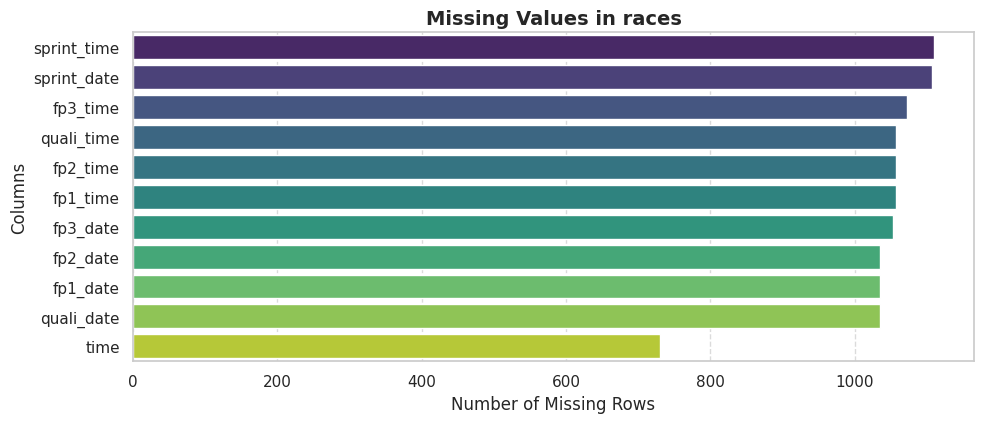


--- constructor_results ---


,Missing Count,Missing Percentage (%)
status,12608,99.87


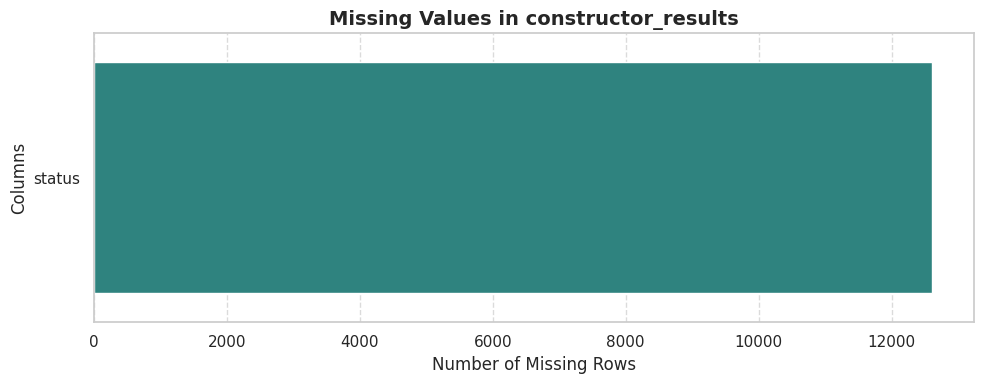


--- drivers ---


,Missing Count,Missing Percentage (%)
number,802,93.15
code,757,87.92


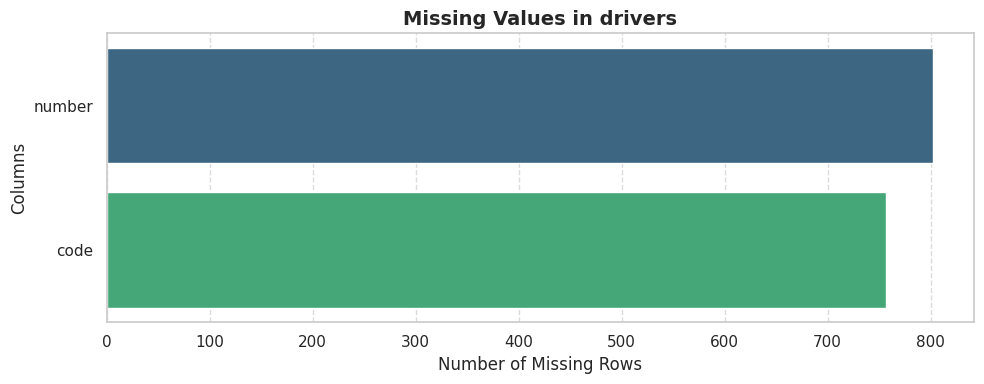


--- constructors ---
No missing values found.

--- lap_times ---
No missing values found.

--- status ---
No missing values found.

--- driver_standings ---
No missing values found.

--- seasons ---
No missing values found.

--- pit_stops ---
No missing values found.

--- sprint_results ---


,Missing Count,Missing Percentage (%)
time,20,5.56
milliseconds,20,5.56
position,15,4.17
fastestLap,9,2.50
fastestLapTime,9,2.50
fastest_lap_seconds,9,2.50


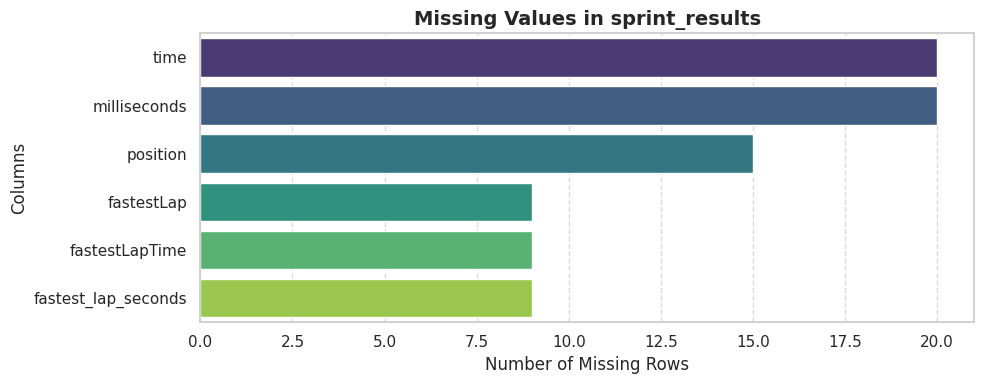


--- constructor_standings ---
No missing values found.

--- results ---


,Missing Count,Missing Percentage (%)
time,19079,71.30
milliseconds,19079,71.30
fastest_lap_seconds,18507,69.16
fastestLap,18507,69.16
fastestLapTime,18507,69.16
fastestLapSpeed,18507,69.16
rank,18249,68.20
position,10953,40.93
number,6,0.02


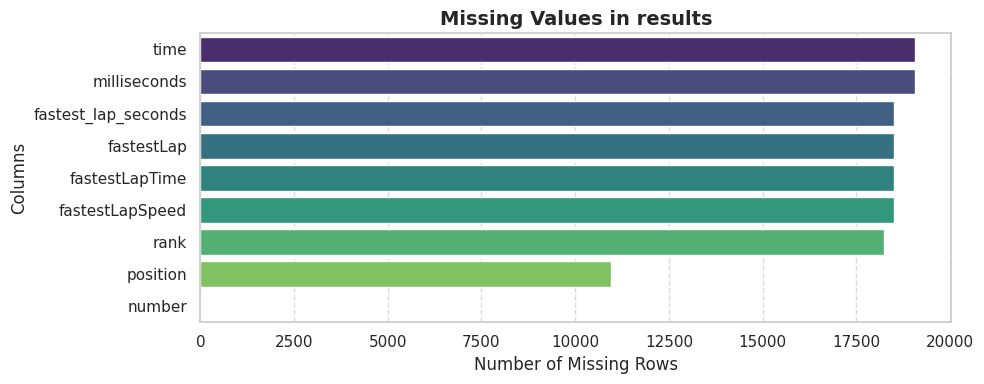


--- circuits ---
No missing values found.

--- qualifying ---


,Missing Count,Missing Percentage (%)
q3_seconds,6865,65.42
q3,6865,65.42
q2_seconds,4647,44.28
q2,4647,44.28
q1,156,1.49
q1_seconds,156,1.49


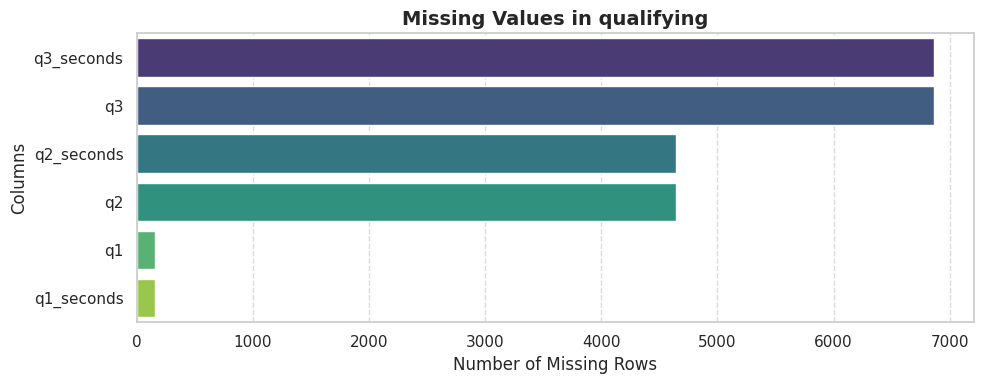

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# checking missing values and plotting
for name, df in data.items():
  missing = df.isnull().sum()
  missing = missing[missing > 0].sort_values(ascending=False)

  print(f"\n--- {name} ---")

  if missing.empty:
    print("No missing values found.")
  else:
    missing_table = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage (%)": (missing / len(df) * 100).round(2),
    })
    display(missing_table)

    # Plotting missing values as a bar chart
    plt.figure(figsize=(10, max(4, len(missing) * 0.4)))
    sns.barplot(
        x=missing.values, y=missing.index, palette="viridis", hue=missing.index
    )
    plt.title(f"Missing Values in {name}", fontsize=14, fontweight="bold")
    plt.xlabel("Number of Missing Rows", fontsize=12)
    plt.ylabel("Columns", fontsize=12)
    plt.grid(axis="x", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.show()

In [30]:
# Grain check: each of these tables should have one row per (raceId, driverId)
for t in ["results", "qualifying", "sprint_results"]:
    df = data[t]
    extra = df.duplicated(["raceId", "driverId"]).sum()
    involved = df.duplicated(["raceId", "driverId"], keep=False).sum()
    print(f"{t}: {extra} extra rows, {involved} rows involved")

results: 91 extra rows, 176 rows involved
qualifying: 0 extra rows, 0 rows involved
sprint_results: 0 extra rows, 0 rows involved


,raceId,driverId,year,rows,constructors,started
0,540,229,1978,2,2,0
1,717,373,1964,2,1,2
2,733,465,1962,2,2,0
3,742,475,1961,2,2,2
4,745,418,1961,2,1,2
5,746,475,1960,2,1,2
6,766,541,1958,2,2,0
7,770,479,1958,2,1,2
8,774,566,1958,2,1,2
9,776,581,1957,2,1,2


,resultId,raceId,year,name,driverId,constructorId,grid,positionOrder,positionText,points,statusId
13188,13189,540,1978,Italian Grand Prix,229,54,0,26,F,0.0,81
13191,13192,540,1978,Italian Grand Prix,229,57,0,29,F,0.0,97
17362,17363,717,1964,United States Grand Prix,373,172,1,7,7,0.0,60
24298,24304,717,1964,United States Grand Prix,373,172,1,12,R,0.0,98
17740,17741,733,1962,British Grand Prix,465,172,0,22,W,0.0,54
17743,17744,733,1962,British Grand Prix,465,97,0,25,W,0.0,54
17961,17962,742,1961,British Grand Prix,475,102,20,19,D,0.0,2
17963,17964,742,1961,British Grand Prix,475,172,5,21,R,0.0,23
18062,18063,745,1961,United States Grand Prix,418,172,11,17,R,0.0,6
24297,24303,745,1961,United States Grand Prix,418,172,15,11,11,0.0,18


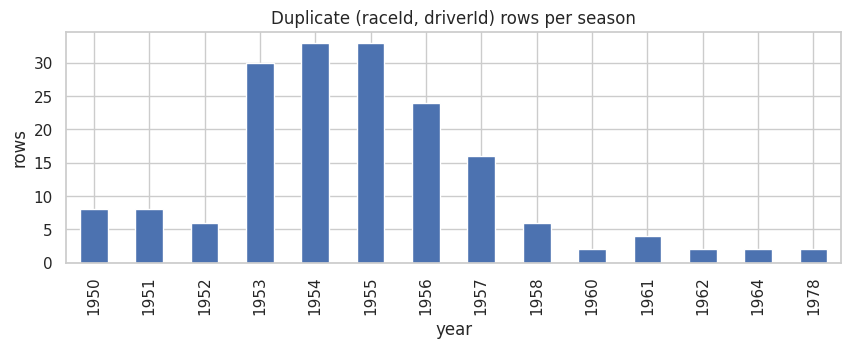

In [31]:
res = data["results"].merge(data["races"][["raceId", "year", "name"]], on="raceId", how="left")
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask].sort_values(["raceId", "driverId", "resultId"])

# Did the driver have different cars in the same race (shared drive)?
summary = (dups.groupby(["raceId", "driverId"])
               .agg(year=("year", "first"), rows=("resultId", "size"),
                    constructors=("constructorId", "nunique"),
                    started=("grid", lambda g: (g > 0).sum()))
               .reset_index())
display(summary.head(20))

display(dups[["resultId", "raceId", "year", "name", "driverId", "constructorId",
              "grid", "positionOrder", "positionText", "points", "statusId"]].head(20))

# Plot: duplicates per season
ax = dups.groupby("year").size().plot(kind="bar", figsize=(10, 3), title="Duplicate (raceId, driverId) rows per season")
ax.set_ylabel("rows")
plt.show()

In [32]:
clean = {k: v.copy() for k, v in data.items()}   # recreated from raw each time, so re-running this cell is safe

r = clean["results"].copy()
r["_grid_rank"] = r["grid"].where(r["grid"] > 0, 999)    # grid 0 (non-start / pit lane) sorts last
#if the pit starts at a value 0 or less then temp change it to 999 to be rakam kebeer
r = r.sort_values(["raceId", "driverId", "_grid_rank", "resultId"])
#sorts By the _grid_rank  then results id ashan law same grid rank yebaa first in

kept = r.drop_duplicates(["raceId", "driverId"], keep="first") #keep first row which is the best row
dropped = r[~r["resultId"].isin(kept["resultId"])]        # keep this for the report
kept = kept.drop(columns="_grid_rank")

assert not kept.duplicated(["raceId", "driverId"]).any()
assert len(kept) + len(dropped) == len(clean["results"])
print(f"results: {len(clean['results'])} -> {len(kept)} rows ({len(dropped)} dropped)")

clean["results"] = kept.sort_values("resultId").reset_index(drop=True)

results: 26759 -> 26668 rows (91 dropped)


=== MISSING VALUES SUMMARY FOR ALL TABLES ===


,Table,Rows,Columns,Missing Values,Columns With Missing Values,Rows With Missing Values,Rows Missing (%)
11,results,26668,19,140748,9,22403,84.01
13,qualifying,10494,12,23336,6,6865,65.42
1,constructor_results,12625,5,12608,1,12608,99.87
0,races,1125,19,11349,11,1125,100.00
2,drivers,861,9,1559,2,802,93.15
9,sprint_results,360,17,82,6,20,5.56
5,status,139,2,0,0,0,0.00
4,lap_times,589081,7,0,0,0,0.00
3,constructors,212,5,0,0,0,0.00
6,driver_standings,34863,7,0,0,0,0.00



=== RACES ===


,Missing Count,Missing (%),Non-Missing Count
sprint_time,1110,98.67,15
sprint_date,1107,98.40,18
fp3_time,1072,95.29,53
quali_time,1057,93.96,68
fp2_time,1057,93.96,68
fp1_time,1057,93.96,68
fp3_date,1053,93.60,72
fp2_date,1035,92.00,90
fp1_date,1035,92.00,90
quali_date,1035,92.00,90


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time,race_year
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009


...


=== QUALIFYING ===


,Missing Count,Missing (%),Non-Missing Count
q3_seconds,6865,65.42,3629
q3,6865,65.42,3629
q2_seconds,4647,44.28,5847
q2,4647,44.28,5847
q1,156,1.49,10338
q1_seconds,156,1.49,10338


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
9,10,18,20,5,15,10,1:26.702,1:25.842,NaN,86.702,85.842,NaN
10,11,18,22,11,17,11,1:26.369,1:26.173,NaN,86.369,86.173,NaN
11,12,18,4,4,5,12,1:26.907,1:26.188,NaN,86.907,86.188,NaN



=== IMPORTANT IDENTIFIER CHECK ===

=== QUALIFYING MISSING VALUES BY YEAR (%) ===


,q1_seconds,q2_seconds,q3_seconds
year,,,
1994,0.26,100.00,100.00
1995,5.74,100.00,100.00
1996,2.03,100.00,100.00
1997,0.45,100.00,100.00
1998,1.31,100.00,100.00
1999,1.54,100.00,100.00
2000,0.00,100.00,100.00
2001,0.00,100.00,100.00
2002,0.00,100.00,100.00


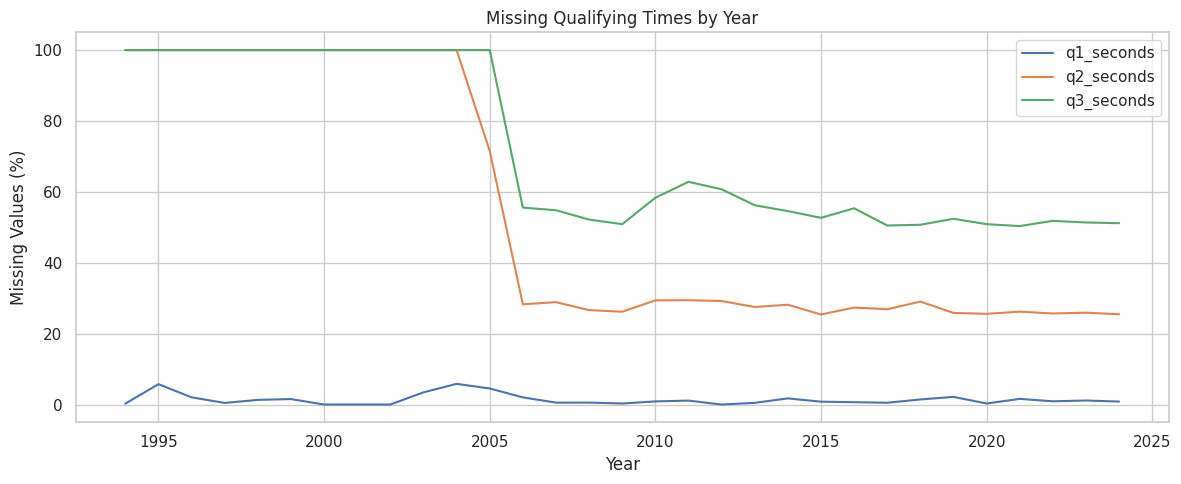


Missing-value inspection completed. No data was modified.


In [33]:

#inspect before we handle missing values

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Inspect missing values in all cleaned tables.
# We only investigate here; no values are filled or removed.

summary = []

for name, df in clean.items():
    missing = df.isna().sum()

    summary.append({
        "Table": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": missing.sum(),
        "Columns With Missing Values": (missing > 0).sum(),
        "Rows With Missing Values": df.isna().any(axis=1).sum(),
        "Rows Missing (%)": round(df.isna().any(axis=1).mean() * 100, 2)
    })

summary_df = pd.DataFrame(summary).sort_values(
    "Missing Values", ascending=False
)

print("=== MISSING VALUES SUMMARY FOR ALL TABLES ===")
display(summary_df)

# Show missing-value counts and percentages for every affected column.
# Percentages help us compare tables of different sizes.

for name, df in clean.items():
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    if missing.empty:
        continue

    print(f"\n=== {name.upper()} ===")

    details = pd.DataFrame({
        "Missing Count": missing,
        "Missing (%)": (missing / len(df) * 100).round(2),
        "Non-Missing Count": len(df) - missing
    })

    display(details)

    # Show up to 3 example records, including their missing columns.
    # This helps identify whether missingness is normal or problematic.
    example_rows = df[df.isna().any(axis=1)].head(3)
    display(example_rows)

# Check identifiers because missing IDs may prevent correct table joins.

print("\n=== IMPORTANT IDENTIFIER CHECK ===")

for name, df in clean.items():
    id_columns = [
        col for col in df.columns
        if col.endswith("Id") or col in ["year", "round"]
    ]

    missing_ids = df[id_columns].isna().sum()
    missing_ids = missing_ids[missing_ids > 0]

    if not missing_ids.empty:
        print(f"\n{name}")
        display(missing_ids)

# Investigate qualifying missingness by year.
# Q2 and Q3 can be absent because a driver did not reach those sessions.
# Older seasons can also have different qualifying formats.

if "qualifying" in clean and "races" in clean:
    q = clean["qualifying"].merge(
        clean["races"][["raceId", "year"]],
        on="raceId",
        how="left"
    )

    time_cols = [
        col for col in ["q1_seconds", "q2_seconds", "q3_seconds"]
        if col in q.columns
    ]

    if time_cols:
        yearly_missing = (
            q.groupby("year")[time_cols]
            .apply(lambda x: x.isna().mean() * 100)
        )

        print("\n=== QUALIFYING MISSING VALUES BY YEAR (%) ===")
        display(yearly_missing.round(2))

        yearly_missing.plot(figsize=(12, 5))
        plt.title("Missing Qualifying Times by Year")
        plt.xlabel("Year")
        plt.ylabel("Missing Values (%)")
        plt.tight_layout()
        plt.show()

print("\nMissing-value inspection completed. No data was modified.")


In [34]:
#HANDLE NULLS
import pandas as pd
import numpy as np

# Use clean created by the duplicate-removal cell.
# The original data dictionary remains unchanged.

def to_seconds(value):
    if pd.isna(value):
        return np.nan

    try:
        parts = str(value).split(":")

        if len(parts) == 3:
            return float(parts[0]) * 3600 + float(parts[1]) * 60 + float(parts[2])

        if len(parts) == 2:
            return float(parts[0]) * 60 + float(parts[1])

        return float(parts[0])

    except (ValueError, TypeError):
        return np.nan


# 1. RACES
# Remove highly incomplete session schedules.
# Keep race date, year, round and circuit information.
# Keep race start time in historical data.

clean["races"] = clean["races"].drop(columns=[
    "fp1_date", "fp1_time",
    "fp2_date", "fp2_time",
    "fp3_date", "fp3_time",
    "quali_date", "quali_time",
    "sprint_date", "sprint_time"
], errors="ignore")


# 2. DRIVERS
# Number and code are mostly missing.
# driverId already identifies the driver.

clean["drivers"] = clean["drivers"].drop(
    columns=["number", "code"],
    errors="ignore"
)


# 3. CONSTRUCTOR RESULTS
# status is almost entirely missing.

clean["constructor_results"] = clean["constructor_results"].drop(
    columns=["status"],
    errors="ignore"
)


# 4. RESULTS
# Restore historical results and fastest-lap statistics.
# Only remove the unnecessary car number.
# Keep official positions and timing records unchanged.

r = clean["results"].copy()

r = r.drop(columns=["number"], errors="ignore")

r["position_missing"] = r["position"].isna().astype(int)

# Recover fastest-lap seconds from recorded strings.
if "fastestLapTime" in r.columns:
    converted = r["fastestLapTime"].apply(to_seconds)

    if "fastest_lap_seconds" not in r.columns:
        r["fastest_lap_seconds"] = converted
    else:
        r["fastest_lap_seconds"] = (
            r["fastest_lap_seconds"].fillna(converted)
        )

# Recover missing fastest-lap measurements from lap_times.
laps = clean["lap_times"].copy()

fastest = (
    laps.sort_values(["raceId", "driverId", "milliseconds", "lap"])
    .drop_duplicates(["raceId", "driverId"])
    [["raceId", "driverId", "lap", "milliseconds"]]
    .rename(columns={
        "lap": "recovered_lap",
        "milliseconds": "recovered_ms"
    })
)

r = r.merge(
    fastest,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

r["fastestLap"] = pd.to_numeric(
    r["fastestLap"], errors="coerce"
).fillna(r["recovered_lap"])

r["fastest_lap_seconds"] = (
    r["fastest_lap_seconds"].fillna(
        r["recovered_ms"] / 1000
    )
)

# Recover fastest-lap rank only for races where
# all retained drivers have recorded fastest-lap times.

r["rank"] = pd.to_numeric(r["rank"], errors="coerce")

complete_race = (
    r.groupby("raceId")["fastest_lap_seconds"]
    .transform(lambda x: x.notna().all())
)

calculated_rank = (
    r.groupby("raceId")["fastest_lap_seconds"]
    .rank(method="min")
)

r["rank"] = r["rank"].fillna(
    calculated_rank.where(complete_race)
)

r["fastest_lap_missing"] = (
    r["fastest_lap_seconds"].isna().astype(int)
)

r = r.drop(columns=[
    "recovered_lap", "recovered_ms"
])

clean["results"] = r


# 5. QUALIFYING
# Restore Q1, Q2 and Q3 seconds.
# Missing Q2/Q3 is meaningful because drivers may
# not have reached those sessions.

q = clean["qualifying"].copy()

for col in ["q1", "q2", "q3"]:
    seconds_col = col + "_seconds"

    if col in q.columns:
        converted = q[col].apply(to_seconds)

        if seconds_col not in q.columns:
            q[seconds_col] = converted
        else:
            q[seconds_col] = (
                q[seconds_col].fillna(converted)
            )

    q["has_" + col + "_time"] = (
        q[seconds_col].notna().astype(int)
    )

# Fill Q1 using the median of earlier races only.
# This avoids using information from future races.
# The indicator preserves which times were originally missing.

q["q1_missing"] = q["q1_seconds"].isna().astype(int)

race_order = (
    clean["races"][["raceId", "date"]]
    .drop_duplicates("raceId")
    .sort_values(["date", "raceId"])
)

q = q.merge(
    race_order,
    on="raceId",
    how="left",
    validate="many_to_one"
)

q = q.sort_values(
    ["date", "raceId", "driverId"]
)

# For each race, calculate the median Q1 time.
race_medians = (
    q.groupby("raceId")["q1_seconds"]
    .median()
    .rename("race_q1_median")
)

race_history = race_order.merge(
    race_medians,
    on="raceId",
    how="left"
).sort_values(["date", "raceId"])

# The median used for each race comes only from
# earlier races, never the current or future races.
past_values = []
previous_times = []

for _, race in race_history.iterrows():
    if previous_times:
        past_values.append(float(np.median(previous_times)))
    else:
        past_values.append(np.nan)

    current_times = q.loc[
        q["raceId"] == race["raceId"], "q1_seconds"
    ].dropna()

    previous_times.extend(current_times.tolist())

race_history["past_q1_median"] = past_values

q = q.merge(
    race_history[["raceId", "past_q1_median"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

q["q1_seconds"] = q["q1_seconds"].fillna(
    q["past_q1_median"]
)

q = q.drop(columns=[
    "q1", "q2", "q3",
    "date", "past_q1_median"
], errors="ignore")

clean["qualifying"] = q.sort_index().reset_index(drop=True)


# 6. SPRINT RESULTS
# Restore sprint fastest-lap information.
# Recover recorded times without inventing official results.

s = clean["sprint_results"].copy()

if "fastestLapTime" in s.columns:
    converted = s["fastestLapTime"].apply(to_seconds)

    if "fastest_lap_seconds" not in s.columns:
        s["fastest_lap_seconds"] = converted
    else:
        s["fastest_lap_seconds"] = (
            s["fastest_lap_seconds"].fillna(converted)
        )

s["position_missing"] = s["position"].isna().astype(int)

s["fastest_lap_missing"] = (
    s["fastest_lap_seconds"].isna().astype(int)
)

# Drop redundant text fastest-lap time.
# Keep the numeric seconds and other historical information.
s = s.drop(
    columns=["fastestLapTime"],
    errors="ignore"
)

clean["sprint_results"] = s


# 7. OTHER TABLES
# No missing values were found in the remaining eight tables.


# 8. SUMMARY

summary = []

for name in data:
    before = data[name]
    after = clean[name]

    summary.append({
        "Table": name,
        "Rows Before": len(before),
        "Rows After": len(after),
        "Columns Before": len(before.columns),
        "Columns After": len(after.columns),
        "Missing Before": int(before.isna().sum().sum()),
        "Missing After": int(after.isna().sum().sum())
    })

print("=== CLEANING SUMMARY ===")
display(pd.DataFrame(summary))


# 9. REMAINING MISSING VALUES

print("\n=== REMAINING MISSING VALUES ===")

for name, df in clean.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print("\n" + name.upper())

        display(pd.DataFrame({
            "Missing Count": missing,
            "Missing (%)": (
                missing / len(df) * 100
            ).round(2)
        }).sort_values("Missing Count", ascending=False))


# 10. FINAL CHECK

print(
    "\nDuplicate race-driver results:",
    clean["results"].duplicated(
        ["raceId", "driverId"]
    ).sum()
)

print("\nCleaning completed.")


=== CLEANING SUMMARY ===


,Table,Rows Before,Rows After,Columns Before,Columns After,Missing Before,Missing After
0,races,1125,1125,19,9,11349,731
1,constructor_results,12625,12625,5,4,12608,0
2,drivers,861,861,9,7,1559,0
3,constructors,212,212,5,5,0,0
4,lap_times,589081,589081,7,7,0,0
5,status,139,139,2,2,0,0
6,driver_standings,34863,34863,7,7,0,0
7,seasons,75,75,2,2,0,0
8,pit_stops,11371,11371,8,8,0,0
9,sprint_results,360,360,17,18,82,73



=== REMAINING MISSING VALUES ===

RACES


,Missing Count,Missing (%)
time,731,64.98



SPRINT_RESULTS


...


RESULTS


,Missing Count,Missing (%)
time,19005,71.27
milliseconds,19005,71.27
fastestLapSpeed,18416,69.06
fastestLapTime,18416,69.06
rank,16972,63.64
fastestLap,15624,58.59
fastest_lap_seconds,15624,58.59
position,10910,40.91



QUALIFYING


,Missing Count,Missing (%)
q3_seconds,6865,65.42
q2_seconds,4647,44.28



Duplicate race-driver results: 0

Cleaning completed.


1. TABLE SIZE BEFORE AND AFTER


,Table,Rows Before,Rows After,Rows Removed,Columns Before,Columns After,Columns Removed
0,races,1125,1125,0,19,9,10
1,constructor_results,12625,12625,0,5,4,1
2,drivers,861,861,0,9,7,2
3,constructors,212,212,0,5,5,0
4,lap_times,589081,589081,0,7,7,0
5,status,139,139,0,2,2,0
6,driver_standings,34863,34863,0,7,7,0
7,seasons,75,75,0,2,2,0
8,pit_stops,11371,11371,0,8,8,0
9,sprint_results,360,360,0,17,18,1


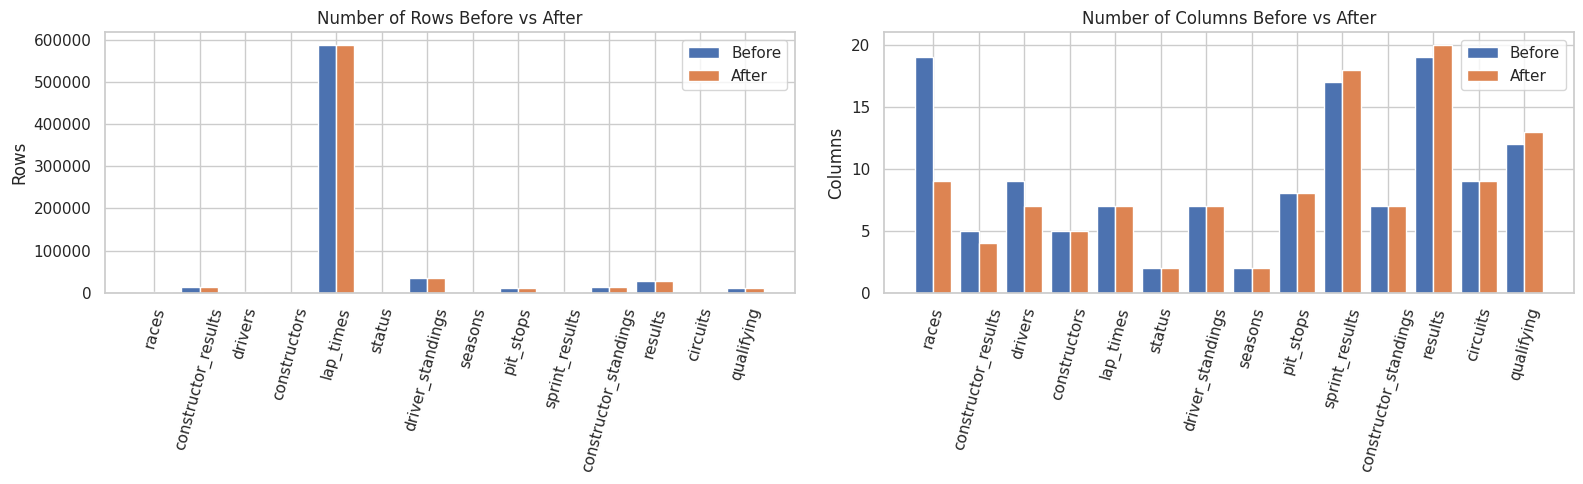


2. MISSING VALUES BEFORE AND AFTER


,Table,Missing Before,Missing After,Missing in Removed Columns,Missing Before in Shared Columns,Missing After in Shared Columns
0,races,11349,731,10618,731,731
1,constructor_results,12608,0,12608,0,0
2,drivers,1559,0,1559,0,0
3,constructors,0,0,0,0,0
4,lap_times,0,0,0,0,0
5,status,0,0,0,0,0
6,driver_standings,0,0,0,0,0
7,seasons,0,0,0,0,0
8,pit_stops,0,0,0,0,0
9,sprint_results,82,73,9,73,73


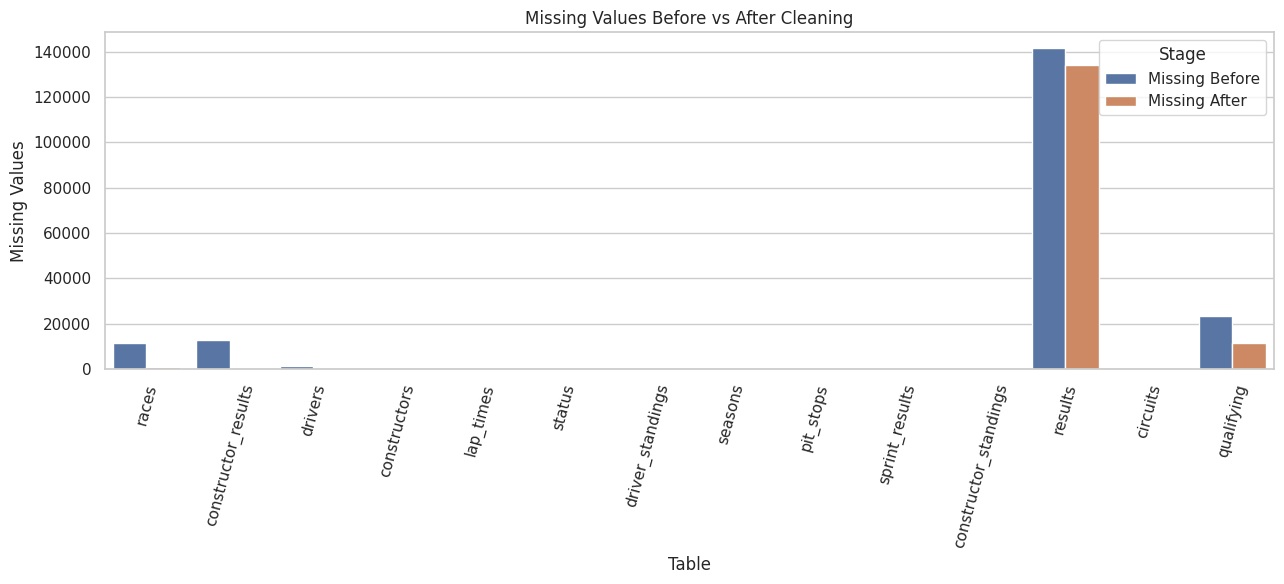


3. MISSING PERCENTAGE BY COLUMN


,Table,Column,Missing Before (%),Missing After (%),Action
0,races,time,64.98,64.98,Kept
1,races,fp1_date,92.00,NaN,Dropped
2,races,fp1_time,93.96,NaN,Dropped
3,races,fp2_date,92.00,NaN,Dropped
4,races,fp2_time,93.96,NaN,Dropped
5,races,fp3_date,93.60,NaN,Dropped
6,races,fp3_time,95.29,NaN,Dropped
7,races,quali_date,92.00,NaN,Dropped
8,races,quali_time,93.96,NaN,Dropped
9,races,sprint_date,98.40,NaN,Dropped


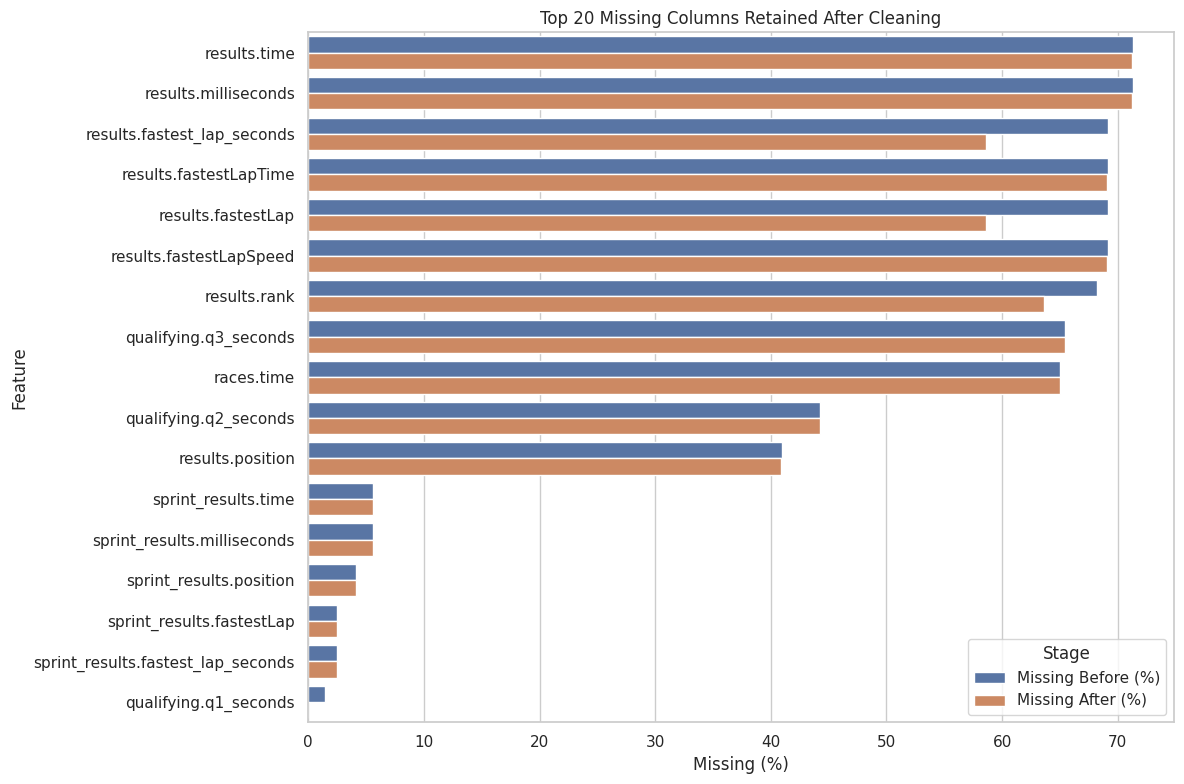


4. DUPLICATES BEFORE AND AFTER


,Table,Duplicates Before,Duplicates After
0,results,91,0
1,qualifying,0,0
2,sprint_results,0,0


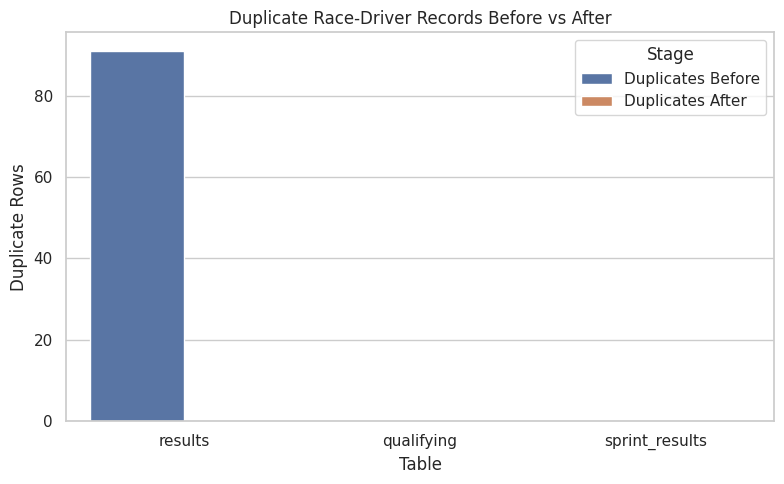


5. PODIUM DISTRIBUTION BEFORE AND AFTER


,Stage,Podium,Not Podium,Podium (%),Missing Position Order
0,Before,3397,23362,12.69,0
1,After,3378,23290,12.67,0


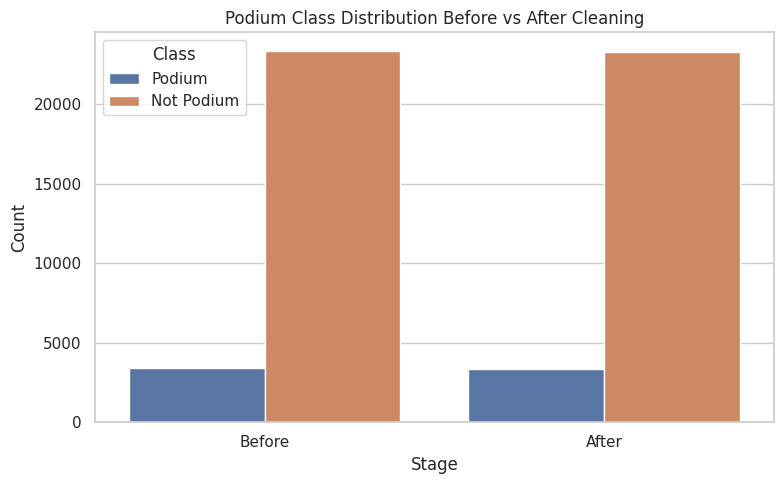


6. DROPPED COLUMNS AND THEIR MISSINGNESS


,Table,Dropped Column,Missing Count,Missing (%)
10,constructor_results,status,12608,99.87
9,races,sprint_time,1110,98.67
8,races,sprint_date,1107,98.40
5,races,fp3_time,1072,95.29
7,races,quali_time,1057,93.96
1,races,fp1_time,1057,93.96
3,races,fp2_time,1057,93.96
4,races,fp3_date,1053,93.60
12,drivers,number,802,93.15
0,races,fp1_date,1035,92.00



7. FINAL CHECKS
races raceId missing: 0
races date missing: 0
results raceId missing: 0
results driverId missing: 0
results positionOrder missing: 0
qualifying raceId missing: 0
qualifying driverId missing: 0
Remaining result duplicates: 0

Before-and-after EDA completed.


In [35]:

#EDA BEFOR VS AFTER

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Compare original data with cleaned data.
# The original tables are not modified.
# Dropped columns are counted separately so that a reduction in
# missing values is not confused with successfully filling values.

# 1. TABLE SIZE COMPARISON
table_summary = []

for name in data:
    before = data[name]
    after = clean[name]

    table_summary.append({
        "Table": name,
        "Rows Before": len(before),
        "Rows After": len(after),
        "Rows Removed": len(before) - len(after),
        "Columns Before": len(before.columns),
        "Columns After": len(after.columns),
        "Columns Removed": len(set(before.columns) - set(after.columns))
    })

table_summary = pd.DataFrame(table_summary)

print("1. TABLE SIZE BEFORE AND AFTER")
display(table_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

x = np.arange(len(table_summary))
w = 0.4

axes[0].bar(x - w/2, table_summary["Rows Before"], w, label="Before")
axes[0].bar(x + w/2, table_summary["Rows After"], w, label="After")
axes[0].set_xticks(x)
axes[0].set_xticklabels(table_summary["Table"], rotation=75)
axes[0].set_title("Number of Rows Before vs After")
axes[0].set_ylabel("Rows")
axes[0].legend()

axes[1].bar(x - w/2, table_summary["Columns Before"], w, label="Before")
axes[1].bar(x + w/2, table_summary["Columns After"], w, label="After")
axes[1].set_xticks(x)
axes[1].set_xticklabels(table_summary["Table"], rotation=75)
axes[1].set_title("Number of Columns Before vs After")
axes[1].set_ylabel("Columns")
axes[1].legend()

plt.tight_layout()
plt.show()


# 2. MISSING VALUES BY TABLE
# This shows the total missing cells remaining in each table.
# A decrease may result from removing columns, not just filling values.

missing_summary = []

for name in data:
    before = data[name]
    after = clean[name]

    common = before.columns.intersection(after.columns)
    removed = before.columns.difference(after.columns)

    missing_summary.append({
        "Table": name,
        "Missing Before": int(before.isna().sum().sum()),
        "Missing After": int(after.isna().sum().sum()),
        "Missing in Removed Columns": int(
            before[removed].isna().sum().sum()
        ),
        "Missing Before in Shared Columns": int(
            before[common].isna().sum().sum()
        ),
        "Missing After in Shared Columns": int(
            after[common].isna().sum().sum()
        )
    })

missing_summary = pd.DataFrame(missing_summary)

print("\n2. MISSING VALUES BEFORE AND AFTER")
display(missing_summary)

plot_data = missing_summary.melt(
    id_vars="Table",
    value_vars=["Missing Before", "Missing After"],
    var_name="Stage",
    value_name="Missing Values"
)

plt.figure(figsize=(13, 6))
sns.barplot(
    data=plot_data,
    x="Table",
    y="Missing Values",
    hue="Stage"
)
plt.title("Missing Values Before vs After Cleaning")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


# 3. MISSING PERCENTAGE FOR EVERY COLUMN
# Removed columns are shown as "Dropped", not as 0% missing.
# This makes the comparison scientifically accurate.

column_summary = []

for name in data:
    before = data[name]
    after = clean[name]

    for col in before.columns:
        before_pct = before[col].isna().mean() * 100

        if col in after.columns:
            after_pct = after[col].isna().mean() * 100
            action = "Kept"
        else:
            after_pct = np.nan
            action = "Dropped"

        if before_pct > 0:
            column_summary.append({
                "Table": name,
                "Column": col,
                "Missing Before (%)": round(before_pct, 2),
                "Missing After (%)": round(after_pct, 2)
                    if pd.notna(after_pct) else np.nan,
                "Action": action
            })

column_summary = pd.DataFrame(column_summary)

print("\n3. MISSING PERCENTAGE BY COLUMN")
display(column_summary)

# Compare missingness only for columns retained in both versions.
shared_missing = column_summary[
    column_summary["Action"] == "Kept"
].copy()

if not shared_missing.empty:
    shared_missing["Feature"] = (
        shared_missing["Table"] + "." + shared_missing["Column"]
    )

    top = shared_missing.sort_values(
        "Missing Before (%)", ascending=False
    ).head(20)

    top_plot = top.melt(
        id_vars="Feature",
        value_vars=[
            "Missing Before (%)",
            "Missing After (%)"
        ],
        var_name="Stage",
        value_name="Missing (%)"
    )

    plt.figure(figsize=(12, 8))
    sns.barplot(
        data=top_plot,
        y="Feature",
        x="Missing (%)",
        hue="Stage"
    )
    plt.title("Top 20 Missing Columns Retained After Cleaning")
    plt.tight_layout()
    plt.show()


# 4. DUPLICATE COMPARISON
# Results, qualifying and sprint_results should have at most
# one record per race-driver combination in our modeling tables.

duplicate_summary = []

for name in ["results", "qualifying", "sprint_results"]:
    before = data[name]
    after = clean[name]

    keys = ["raceId", "driverId"]

    duplicate_summary.append({
        "Table": name,
        "Duplicates Before": int(before.duplicated(keys).sum()),
        "Duplicates After": int(after.duplicated(keys).sum())
    })

duplicate_summary = pd.DataFrame(duplicate_summary)

print("\n4. DUPLICATES BEFORE AND AFTER")
display(duplicate_summary)

duplicate_plot = duplicate_summary.melt(
    id_vars="Table",
    var_name="Stage",
    value_name="Duplicate Rows"
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=duplicate_plot,
    x="Table",
    y="Duplicate Rows",
    hue="Stage"
)
plt.title("Duplicate Race-Driver Records Before vs After")
plt.tight_layout()
plt.show()


# 5. PODIUM DISTRIBUTION
# Compare class balance before and after duplicate removal.
# positionOrder is used here as the provisional podium definition.

podium_summary = []

for stage, df in [
    ("Before", data["results"]),
    ("After", clean["results"])
]:
    valid = df["positionOrder"].notna()
    positions = df.loc[valid, "positionOrder"]

    podium = positions.between(1, 3).sum()
    not_podium = len(positions) - podium

    podium_summary.append({
        "Stage": stage,
        "Podium": int(podium),
        "Not Podium": int(not_podium),
        "Podium (%)": round(podium / len(positions) * 100, 2)
            if len(positions) else np.nan,
        "Missing Position Order": int((~valid).sum())
    })

podium_summary = pd.DataFrame(podium_summary)

print("\n5. PODIUM DISTRIBUTION BEFORE AND AFTER")
display(podium_summary)

podium_plot = podium_summary.melt(
    id_vars="Stage",
    value_vars=["Podium", "Not Podium"],
    var_name="Class",
    value_name="Count"
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=podium_plot,
    x="Stage",
    y="Count",
    hue="Class"
)
plt.title("Podium Class Distribution Before vs After Cleaning")
plt.tight_layout()
plt.show()


# 6. SUMMARY OF DROPPED COLUMNS
# Document exactly which features were removed and their missingness.
# This justifies feature removal instead of hiding missing values.

removed_summary = []

for name in data:
    removed = data[name].columns.difference(clean[name].columns)

    for col in removed:
        removed_summary.append({
            "Table": name,
            "Dropped Column": col,
            "Missing Count": int(data[name][col].isna().sum()),
            "Missing (%)": round(
                data[name][col].isna().mean() * 100, 2
            )
        })

print("\n6. DROPPED COLUMNS AND THEIR MISSINGNESS")

if removed_summary:
    display(pd.DataFrame(removed_summary).sort_values(
        "Missing (%)", ascending=False
    ))
else:
    print("No columns were dropped.")


# 7. FINAL DATA QUALITY CHECKS
# Confirm that cleaning did not create missing identifiers
# or leave duplicate race-driver records in results.

print("\n7. FINAL CHECKS")

for name, columns in {
    "races": ["raceId", "date"],
    "results": ["raceId", "driverId", "positionOrder"],
    "qualifying": ["raceId", "driverId"]
}.items():
    for col in columns:
        if col in clean[name].columns:
            print(
                name, col,
                "missing:", int(clean[name][col].isna().sum())
            )

print(
    "Remaining result duplicates:",
    clean["results"].duplicated(["raceId", "driverId"]).sum()
)

print("\nBefore-and-after EDA completed.")


=== FRONT-ROW STARTERS ===
Total front-row starts: 2259
Total podiums: 1347

=== FRONT-ROW PODIUM CONVERSION BY CIRCUIT ===


,circuit,era,starts,podiums,podium_rate
68,Miami International Autodrome,2014 onwards,6,6,100.00
93,Suzuka Circuit,2014 onwards,18,16,88.89
29,Circuit Park Zandvoort,2014 onwards,8,7,87.50
58,Jeddah Corniche Circuit,2014 onwards,8,7,87.50
97,Yas Marina Circuit,2014 onwards,22,19,86.36
...,...,...,...,...,...
84,Scandinavian Raceway,Before 2014,12,5,41.67
22,Brands Hatch,Before 2014,28,11,39.29
13,Autódromo Internacional Nelson Piquet,Before 2014,20,7,35.00
45,Detroit Street Circuit,Before 2014,14,4,28.57



=== TOP 5 CIRCUITS BEFORE 2014 ===


,circuit,era,starts,podiums,podium_rate
23,Buddh International Circuit,Before 2014,6,5,83.33
37,Circuit de Nevers Magny-Cours,Before 2014,36,29,80.56
56,Istanbul Park,Before 2014,14,11,78.57
46,Dijon-Prenois,Before 2014,12,9,75.00
94,Suzuka Circuit,Before 2014,50,35,70.00



=== TOP 5 CIRCUITS FROM 2014 ONWARDS ===


,circuit,era,starts,podiums,podium_rate
68,Miami International Autodrome,2014 onwards,6,6,100.00
93,Suzuka Circuit,2014 onwards,18,16,88.89
29,Circuit Park Zandvoort,2014 onwards,8,7,87.50
58,Jeddah Corniche Circuit,2014 onwards,8,7,87.50
97,Yas Marina Circuit,2014 onwards,22,19,86.36


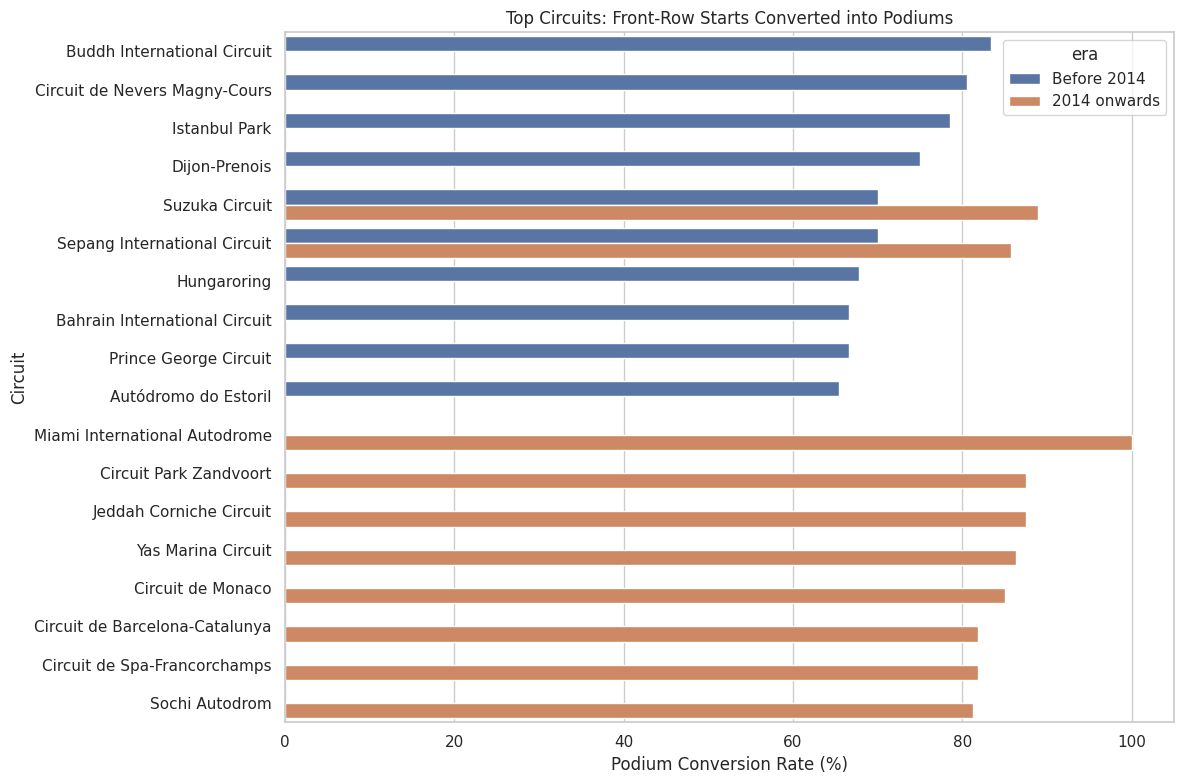


=== QUALIFYING POSITION VS STARTING GRID ===
Drivers compared: 10407
Drivers with different qualifying and grid positions: 2422
Missing qualifying positions: 16174


,raceId,driverId,year,circuit,qualifying_position,grid
3,18,4,2008,Albert Park Grand Prix Circuit,12.0,11
5,18,6,2008,Albert Park Grand Prix Circuit,14.0,13
6,18,7,2008,Albert Park Grand Prix Circuit,18.0,17
7,18,8,2008,Albert Park Grand Prix Circuit,16.0,15
9,18,10,2008,Albert Park Grand Prix Circuit,9.0,18
10,18,11,2008,Albert Park Grand Prix Circuit,20.0,19
11,18,12,2008,Albert Park Grand Prix Circuit,21.0,20
15,18,16,2008,Albert Park Grand Prix Circuit,19.0,22
16,18,17,2008,Albert Park Grand Prix Circuit,15.0,14
17,18,18,2008,Albert Park Grand Prix Circuit,13.0,12



=== CIRCUIT RANKING BEFORE VS AFTER 2014 ===


era,2014 onwards,Before 2014,Rank Before,Rank After,Rank Change
circuit,,,,,
Suzuka Circuit,88.89,70.00,1,1,0
Circuit Park Zandvoort,87.50,58.33,12,2,10
Yas Marina Circuit,86.36,60.00,8,3,5
Sepang International Circuit,85.71,70.00,1,4,-3
Circuit de Monaco,85.00,48.76,20,5,15
Circuit de Barcelona-Catalunya,81.82,65.22,5,6,-1
Circuit de Spa-Francorchamps,81.82,53.26,17,6,11
Autódromo José Carlos Pace,78.95,59.68,10,8,2
Shanghai International Circuit,78.57,65.00,6,9,-3



=== RANKING CHANGE SUMMARY ===
Circuits compared: 21
Circuits with changed rankings: 18


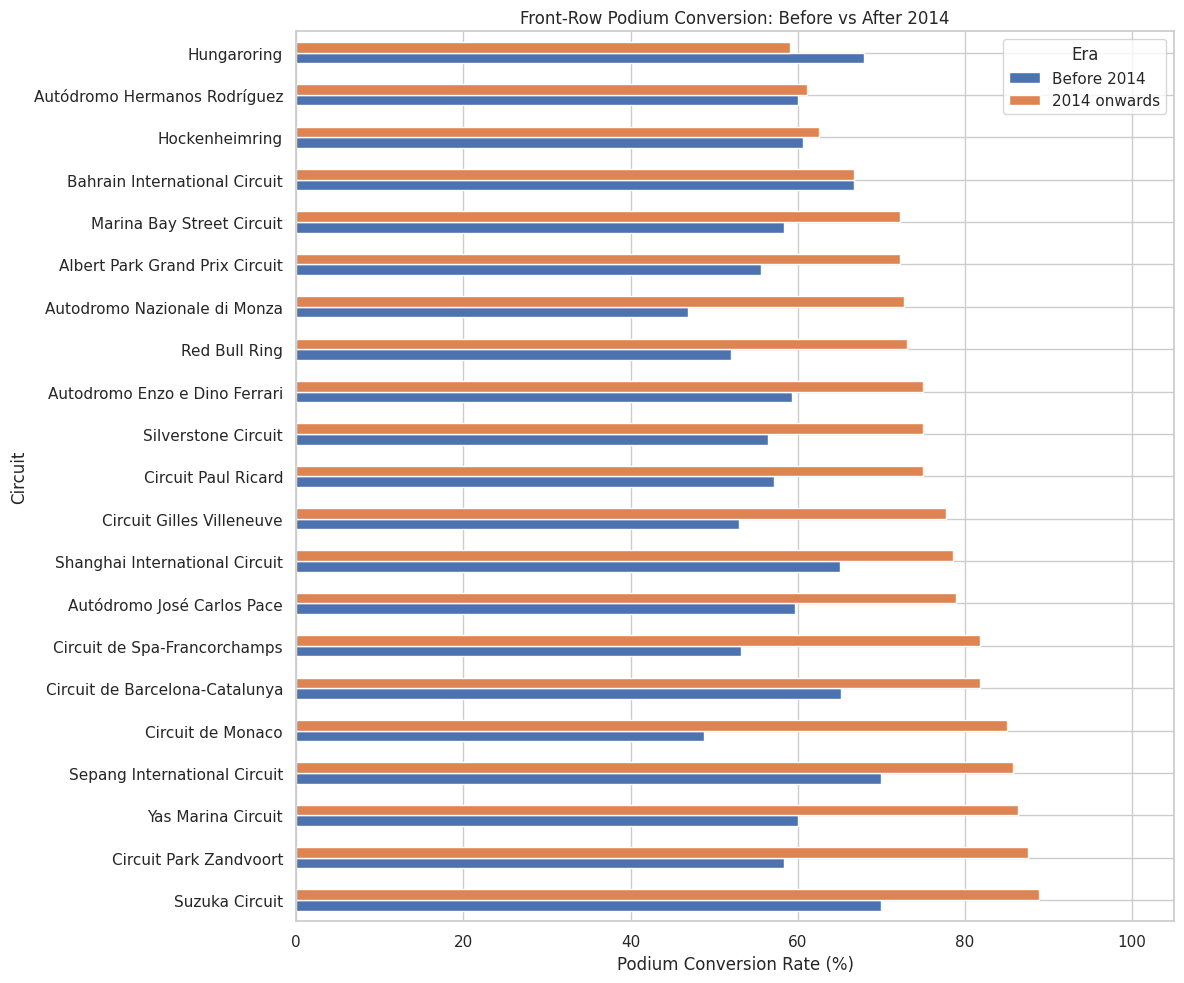


=== QUESTION 1 ANSWER ===
Highest before 2014: Buddh International Circuit (83.33%, 5/6 starts)
Highest from 2014 onwards: Miami International Autodrome (100.00%, 6/6 starts)
Among 21 circuits present in both eras, 18 changed ranking.

Note: Ranking changes are calculated only among circuits with enough starts in both eras.


In [36]:
# QUESTION 1: FRONT-ROW START TO PODIUM CONVERSION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. JOIN THE REQUIRED TABLES

df = clean["results"][[
    "raceId", "driverId", "grid", "positionOrder"
]].merge(
    clean["races"][["raceId", "year", "circuitId"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["circuits"][["circuitId", "name"]],
    on="circuitId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["qualifying"][[
        "raceId", "driverId", "position"
    ]].rename(
        columns={"position": "qualifying_position"}
    ),
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

df = df.rename(columns={"name": "circuit"})

df["grid"] = pd.to_numeric(df["grid"], errors="coerce")
df["positionOrder"] = pd.to_numeric(
    df["positionOrder"], errors="coerce"
)
df["qualifying_position"] = pd.to_numeric(
    df["qualifying_position"], errors="coerce"
)

# 2. DEFINE PODIUM AND ERAS

# A podium means finishing in positions 1, 2 or 3.
df["podium"] = df["positionOrder"].between(1, 3).astype(int)

df["era"] = np.where(
    df["year"] < 2014,
    "Before 2014",
    "2014 onwards"
)

# 3. SELECT FRONT-ROW STARTERS

# Front row means actual starting grid position 1 or 2.
front = df[df["grid"].isin([1, 2])].copy()

print("=== FRONT-ROW STARTERS ===")
print("Total front-row starts:", len(front))
print("Total podiums:", front["podium"].sum())

# 4. CALCULATE PODIUM CONVERSION RATE

rates_all = front.groupby(
    ["circuit", "era"]
).agg(
    starts=("podium", "size"),
    podiums=("podium", "sum")
).reset_index()

rates_all["podium_rate"] = (
    rates_all["podiums"] / rates_all["starts"] * 100
)

# Require at least 5 front-row starts per circuit and era.
# This reduces the effect of very small samples.
rates = rates_all[
    rates_all["starts"] >= 5
].copy()

rates = rates.sort_values(
    ["era", "podium_rate", "starts"],
    ascending=[True, False, False]
)

print("\n=== FRONT-ROW PODIUM CONVERSION BY CIRCUIT ===")
display(rates.round(2))

# 5. SHOW TOP 5 CIRCUITS IN EACH ERA

before = rates[
    rates["era"] == "Before 2014"
].sort_values(
    ["podium_rate", "starts"],
    ascending=[False, False]
)

after = rates[
    rates["era"] == "2014 onwards"
].sort_values(
    ["podium_rate", "starts"],
    ascending=[False, False]
)

print("\n=== TOP 5 CIRCUITS BEFORE 2014 ===")
display(before.head(5).round(2))

print("\n=== TOP 5 CIRCUITS FROM 2014 ONWARDS ===")
display(after.head(5).round(2))

# 6. VISUALIZE TOP CIRCUITS IN EACH ERA

top = pd.concat([
    before.head(10),
    after.head(10)
])

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top,
    x="podium_rate",
    y="circuit",
    hue="era",
    hue_order=["Before 2014", "2014 onwards"]
)

plt.title("Top Circuits: Front-Row Starts Converted into Podiums")
plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.xlim(0, 105)
plt.tight_layout()
plt.show()

# 7. COMPARE QUALIFYING POSITION WITH ACTUAL GRID

# Only compare records with valid grid and qualifying positions.
# A grid of 0 is not a normal starting grid position.
comparison = df[
    (df["grid"] > 0) &
    (df["qualifying_position"] > 0)
].copy()

comparison["grid_changed"] = (
    comparison["grid"] != comparison["qualifying_position"]
)

print("\n=== QUALIFYING POSITION VS STARTING GRID ===")
print("Drivers compared:", len(comparison))
print(
    "Drivers with different qualifying and grid positions:",
    comparison["grid_changed"].sum()
)

print(
    "Missing qualifying positions:",
    df["qualifying_position"].isna().sum()
)

display(
    comparison.loc[
        comparison["grid_changed"],
        [
            "raceId", "driverId", "year",
            "circuit", "qualifying_position", "grid"
        ]
    ].head(10)
)

# 8. COMPARE CIRCUITS THAT APPEAR IN BOTH ERAS

# Only circuits with at least 5 front-row starts
# in each era are included in this comparison.

comparison_rates = rates.pivot(
    index="circuit",
    columns="era",
    values="podium_rate"
).dropna().copy()

comparison_rates["Rank Before"] = (
    comparison_rates["Before 2014"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison_rates["Rank After"] = (
    comparison_rates["2014 onwards"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Positive = improved ranking after 2014.
# Negative = dropped in ranking after 2014.
comparison_rates["Rank Change"] = (
    comparison_rates["Rank Before"] -
    comparison_rates["Rank After"]
)

comparison_rates = comparison_rates.sort_values(
    "Rank After"
)

print("\n=== CIRCUIT RANKING BEFORE VS AFTER 2014 ===")
display(comparison_rates.round(2))

print("\n=== RANKING CHANGE SUMMARY ===")
print("Circuits compared:", len(comparison_rates))
print(
    "Circuits with changed rankings:",
    (comparison_rates["Rank Change"] != 0).sum()
)

# 9. VISUALIZE BEFORE VS AFTER 2014 FOR THE SAME CIRCUITS

comparison_rates[
    ["Before 2014", "2014 onwards"]
].plot(
    kind="barh",
    figsize=(12, 10)
)

plt.title("Front-Row Podium Conversion: Before vs After 2014")
plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.xlim(0, 105)
plt.legend(title="Era")
plt.tight_layout()
plt.show()

# 10. PRINT THE ANSWER AUTOMATICALLY

print("\n=== QUESTION 1 ANSWER ===")

if not before.empty:
    best_before = before.iloc[0]
    print(
        f"Highest before 2014: {best_before['circuit']} "
        f"({best_before['podium_rate']:.2f}%, "
        f"{int(best_before['podiums'])}/"
        f"{int(best_before['starts'])} starts)"
    )

if not after.empty:
    best_after = after.iloc[0]
    print(
        f"Highest from 2014 onwards: {best_after['circuit']} "
        f"({best_after['podium_rate']:.2f}%, "
        f"{int(best_after['podiums'])}/"
        f"{int(best_after['starts'])} starts)"
    )

changed = (comparison_rates["Rank Change"] != 0).sum()

print(
    f"Among {len(comparison_rates)} circuits present "
    f"in both eras, {changed} changed ranking."
)

print(
    "\nNote: Ranking changes are calculated only "
    "among circuits with enough starts in both eras."
)

In [37]:
### Question 1 — Front-Row to Podium Conversion

##The analysis joins results, races, circuits, and qualifying at the driver-race level. A front-row start means grid position 1 or 2, and a podium means finishing in the top 3.

##The podium conversion rate is calculated for each circuit before 2014 and from 2014 onwards. Circuits with fewer than 5 front-row starts per era are excluded to reduce the effect of small samples. Rankings are compared for circuits appearing in both periods.

##Actual starting grid is used instead of qualifying position because penalties can change a driver's starting position. Missing qualifying positions are excluded from that comparison, but do not prevent the use of valid grid results.

##Grid position is known before the race, while the finishing position is only known afterward.

=== UNMAPPED NATIONALITIES ===
['American-Italian', 'Argentine-Italian']

Rows before filtering: 26668
Rows after filtering: 25030

=== OVERALL HOME VS AWAY PODIUM RATES ===


,starts,podiums,podium_rate
home_race,,,
False,22708,3118,13.73
True,2322,260,11.20



=== PODIUM RATES BY STARTING GRID ===


,grid_group,home_race,starts,podiums,podium_rate
0,1-3,False,3118,1725,55.32
1,1-3,True,267,142,53.18
6,4-6,False,3114,810,26.01
7,4-6,True,264,63,23.86
8,7-10,False,4116,379,9.21
9,7-10,True,388,33,8.51
2,11-15,False,5123,151,2.95
3,11-15,True,470,15,3.19
4,16+,False,7237,53,0.73
5,16+,True,933,7,0.75


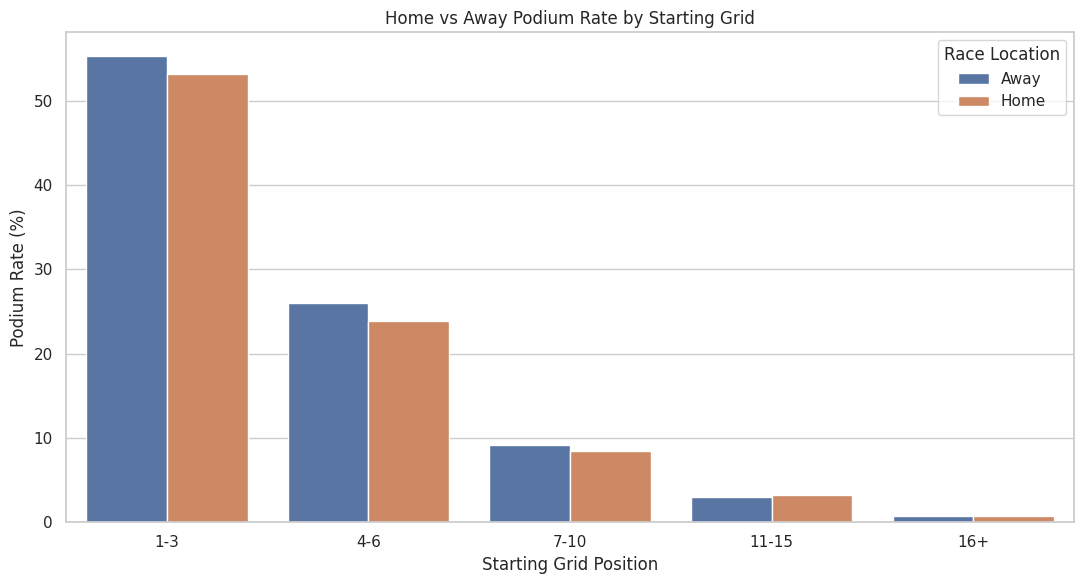


=== HOME ADVANTAGE BY GRID GROUP ===


home_race,Away (%),Home (%),Difference (pp)
grid_group,,,
1-3,55.32,53.18,-2.14
4-6,26.01,23.86,-2.15
7-10,9.21,8.51,-0.70
11-15,2.95,3.19,0.24
16+,0.73,0.75,0.02



=== GRID-ADJUSTED PODIUM RATES ===
Home: 12.90%
Away: 13.55%
Difference: -0.65 percentage points

=== QUESTION 2 ANSWER ===
Drivers had a lower podium rate at home after controlling for starting position.
Note: Nationality is used as a proxy for home country. Dual or unknown nationalities are excluded.


In [38]:
# QUESTION 2: HOME-COUNTRY PODIUM ADVANTAGE

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Join results, races, circuits and drivers.
home = clean["results"][[
    "raceId", "driverId", "grid", "positionOrder"
]].merge(
    clean["races"][["raceId", "circuitId"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["circuits"][["circuitId", "country"]],
    on="circuitId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["drivers"][["driverId", "nationality"]],
    on="driverId",
    how="inner",
    validate="many_to_one"
)

# 2. Convert driver nationalities to countries.
home["nationality"] = home["nationality"].str.strip()

nationality_to_country = {
    "American": "USA",
    "Argentine": "Argentina",
    "Argentinian": "Argentina",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Belgian": "Belgium",
    "Brazilian": "Brazil",
    "British": "UK",
    "Canadian": "Canada",
    "Chinese": "China",
    "Colombian": "Colombia",
    "Czech": "Czech Republic",
    "Danish": "Denmark",
    "Dutch": "Netherlands",
    "Finnish": "Finland",
    "French": "France",
    "German": "Germany",
    "Hungarian": "Hungary",
    "Indian": "India",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Italian": "Italy",
    "Japanese": "Japan",
    "Malaysian": "Malaysia",
    "Mexican": "Mexico",
    "Monegasque": "Monaco",
    "New Zealander": "New Zealand",
    "Polish": "Poland",
    "Portuguese": "Portugal",
    "Russian": "Russia",
    "South African": "South Africa",
    "Spanish": "Spain",
    "Swedish": "Sweden",
    "Swiss": "Switzerland",
    "Thai": "Thailand",
    "Uruguayan": "Uruguay",
    "Venezuelan": "Venezuela",
    "Chilean": "Chile",
    "East German": "Germany",
    "Liechtensteiner": "Liechtenstein",
    "Rhodesian": "Zimbabwe"
}

# Dual nationalities are ambiguous, so exclude them.
home["driver_country"] = home["nationality"].map(
    nationality_to_country
)

country_aliases = {
    "United States": "USA",
    "United Kingdom": "UK",
    "Great Britain": "UK",
    "UAE": "United Arab Emirates",
    "Korea": "South Korea"
}

home["circuit_country"] = home["country"].replace(
    country_aliases
)

home["driver_country"] = home["driver_country"].replace(
    country_aliases
)

print("=== UNMAPPED NATIONALITIES ===")
print(sorted(
    home.loc[
        home["driver_country"].isna(),
        "nationality"
    ].dropna().unique()
))

# 3. Remove rows with invalid grid or unknown country.
home["grid"] = pd.to_numeric(
    home["grid"], errors="coerce"
)

home["positionOrder"] = pd.to_numeric(
    home["positionOrder"], errors="coerce"
)

print("\nRows before filtering:", len(home))

home = home[
    (home["grid"] > 0) &
    home["positionOrder"].notna() &
    home["driver_country"].notna() &
    home["circuit_country"].notna()
].copy()

print("Rows after filtering:", len(home))

# 4. Identify home races and podium finishes.
home["home_race"] = (
    home["driver_country"] == home["circuit_country"]
)

home["podium"] = home["positionOrder"].between(
    1, 3
).astype(int)

# 5. Overall podium rates.
overall = home.groupby("home_race")["podium"].agg(
    starts="size",
    podiums="sum",
    podium_rate="mean"
)

overall["podium_rate"] *= 100

print("\n=== OVERALL HOME VS AWAY PODIUM RATES ===")
display(overall.round(2))

# 6. Group similar starting grid positions.
def grid_group(grid):
    if grid <= 3:
        return "1-3"
    elif grid <= 6:
        return "4-6"
    elif grid <= 10:
        return "7-10"
    elif grid <= 15:
        return "11-15"
    else:
        return "16+"

home["grid_group"] = home["grid"].apply(grid_group)

grid_order = ["1-3", "4-6", "7-10", "11-15", "16+"]

# 7. Calculate podium rates for each starting group.
grid_rates = home.groupby(
    ["grid_group", "home_race"]
)["podium"].agg(
    starts="size",
    podiums="sum",
    podium_rate="mean"
).reset_index()

grid_rates["podium_rate"] *= 100

grid_rates["grid_group"] = pd.Categorical(
    grid_rates["grid_group"],
    categories=grid_order,
    ordered=True
)

grid_rates = grid_rates.sort_values(
    ["grid_group", "home_race"]
)

print("\n=== PODIUM RATES BY STARTING GRID ===")
display(grid_rates.round(2))

# 8. Visualize home vs away for each grid group.
plt.figure(figsize=(11, 6))

sns.barplot(
    data=grid_rates,
    x="grid_group",
    y="podium_rate",
    hue="home_race",
    hue_order=[False, True],
    order=grid_order,
    errorbar=None
)

plt.title("Home vs Away Podium Rate by Starting Grid")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")
plt.legend(
    title="Race Location",
    labels=["Away", "Home"]
)
plt.tight_layout()
plt.show()

# 9. Compare home and away rates directly.
comparison2 = grid_rates.pivot(
    index="grid_group",
    columns="home_race",
    values="podium_rate"
)

comparison2 = comparison2.rename(
    columns={
        False: "Away (%)",
        True: "Home (%)"
    }
)

comparison2["Difference (pp)"] = (
    comparison2["Home (%)"] - comparison2["Away (%)"]
)

print("\n=== HOME ADVANTAGE BY GRID GROUP ===")
display(comparison2.round(2))

# 10. Calculate grid-adjusted podium rates.
# Use identical grid-group weights for home and away.
counts = home["grid_group"].value_counts(
    normalize=True
)

valid_groups = comparison2.dropna(
    subset=["Home (%)", "Away (%)"]
).index

weights = counts.reindex(valid_groups)
weights = weights / weights.sum()

adjusted_home = (
    comparison2.loc[valid_groups, "Home (%)"] * weights
).sum()

adjusted_away = (
    comparison2.loc[valid_groups, "Away (%)"] * weights
).sum()

difference = adjusted_home - adjusted_away

print("\n=== GRID-ADJUSTED PODIUM RATES ===")
print(f"Home: {adjusted_home:.2f}%")
print(f"Away: {adjusted_away:.2f}%")
print(f"Difference: {difference:+.2f} percentage points")

# 11. Print the answer.
print("\n=== QUESTION 2 ANSWER ===")

if difference > 0:
    print(
        "Drivers had a higher podium rate at home "
        "after controlling for starting position."
    )
elif difference < 0:
    print(
        "Drivers had a lower podium rate at home "
        "after controlling for starting position."
    )
else:
    print(
        "Home and away podium rates were equal "
        "after controlling for starting position."
    )

print(
    "Note: Nationality is used as a proxy for home country. "
    "Dual or unknown nationalities are excluded."
)

In [39]:
### Question 2 — Home-Country Podium Advantage

##We joined results, races, circuits, and drivers to compare home and away podium rates. Each row represents one driver in one race.

##After grouping drivers by similar starting grid positions, the adjusted podium rate was **12.90% at home** and **13.55% away**, a difference of **−0.65 percentage points**.

##Therefore, the data shows **no home-country podium advantage** after controlling for starting position.

##Rows with invalid starting grids or unknown nationalities were excluded. Driver nationality was used as an approximation of home country. Starting grid is known before the race, while podium position is a post-race outcome.

=== NON-START ENTRIES EXCLUDED ===


,status,count
0,Withdrew,14



=== MECHANICAL FAILURE REASONS ===


,status,count
0,Engine,81
1,Brakes,49
2,Gearbox,42
3,Power Unit,42
4,Suspension,25
5,Hydraulics,15
6,Electrical,14
7,Power loss,13
8,Wheel,11
9,Oil leak,10



=== MECHANICAL FAILURES WITH ZERO LAPS ===
Total: 24


,year,constructor,status,grid,laps
22345,2014,Caterham,Power Unit,20,0
22458,2015,Lotus F1,Power loss,8,0
22482,2015,Manor Marussia,Fuel system,0,0
22522,2015,McLaren,ERS,20,0
22622,2015,Sauber,Gearbox,16,0
22662,2015,Force India,Power loss,11,0
22865,2016,Ferrari,Engine,3,0
22866,2016,Renault,Hydraulics,19,0
23344,2017,McLaren,Power Unit,17,0
23364,2017,McLaren,Power Unit,15,0



=== MECHANICAL RETIREMENT RATES BY CONSTRUCTOR ===


,constructor,period,starts,mechanical_retirements,retirement_rate
8,Caterham,2014-2021,34,8,23.53
14,Lotus F1,2014-2021,75,13,17.33
28,Toro Rosso,2014-2021,242,38,15.70
17,McLaren,2014-2021,318,46,14.47
25,Renault,2014-2021,200,28,14.00
26,Sauber,2014-2021,200,22,11.00
23,Red Bull,2014-2021,319,33,10.34
2,AlphaTauri,2014-2021,78,8,10.26
16,Marussia,2014-2021,31,3,9.68
12,Haas F1 Team,2014-2021,241,23,9.54



=== TOP 10 CONSTRUCTORS IN EACH PERIOD ===


,constructor,period,starts,mechanical_retirements,retirement_rate
8,Caterham,2014-2021,34,8,23.53
14,Lotus F1,2014-2021,75,13,17.33
28,Toro Rosso,2014-2021,242,38,15.70
17,McLaren,2014-2021,318,46,14.47
25,Renault,2014-2021,200,28,14.00
26,Sauber,2014-2021,200,22,11.00
23,Red Bull,2014-2021,319,33,10.34
2,AlphaTauri,2014-2021,78,8,10.26
16,Marussia,2014-2021,31,3,9.68
12,Haas F1 Team,2014-2021,241,23,9.54


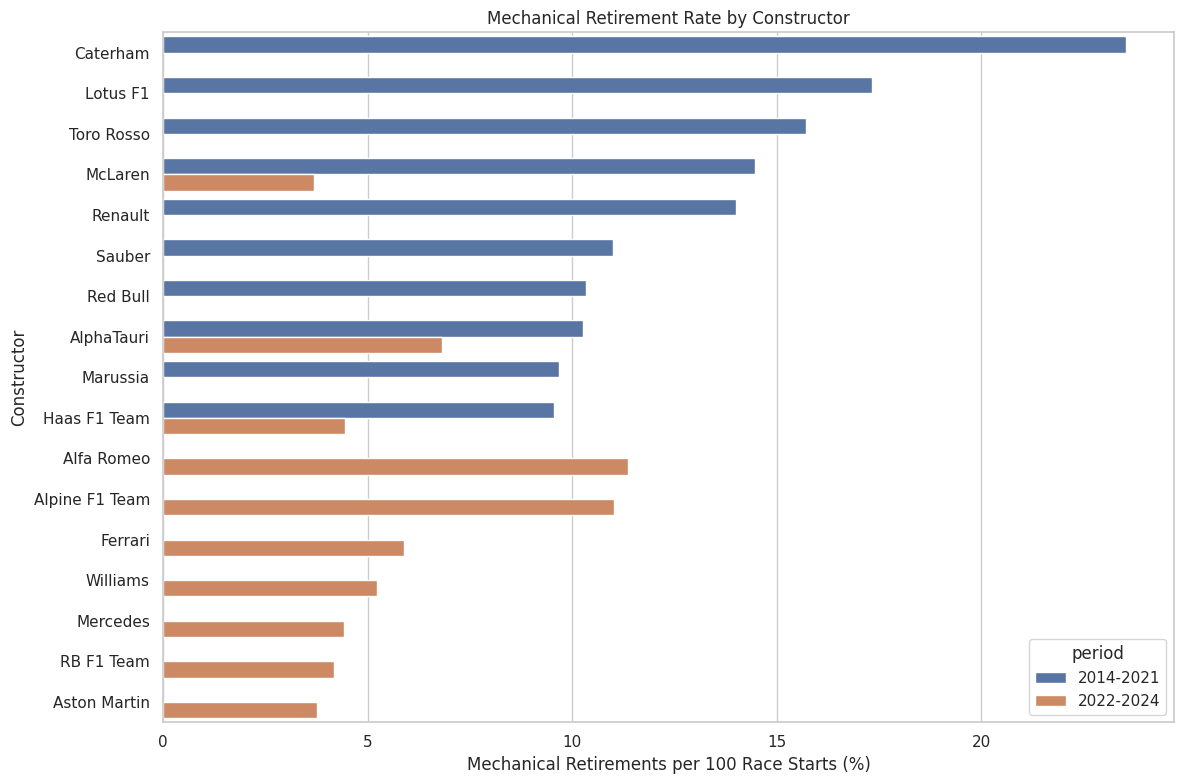


=== CONSTRUCTOR COMPARISON BETWEEN PERIODS ===


period,2014-2021,2022-2024,Difference (pp)
constructor,,,
Alfa Romeo,4.17,11.36,7.20
Alpine F1 Team,6.82,11.03,4.21
Aston Martin,2.27,3.76,1.49
Mercedes,4.06,4.41,0.35
Ferrari,6.25,5.88,-0.37
Williams,7.52,5.22,-2.30
AlphaTauri,10.26,6.82,-3.44
Haas F1 Team,9.54,4.44,-5.10
Red Bull,10.34,3.68,-6.67


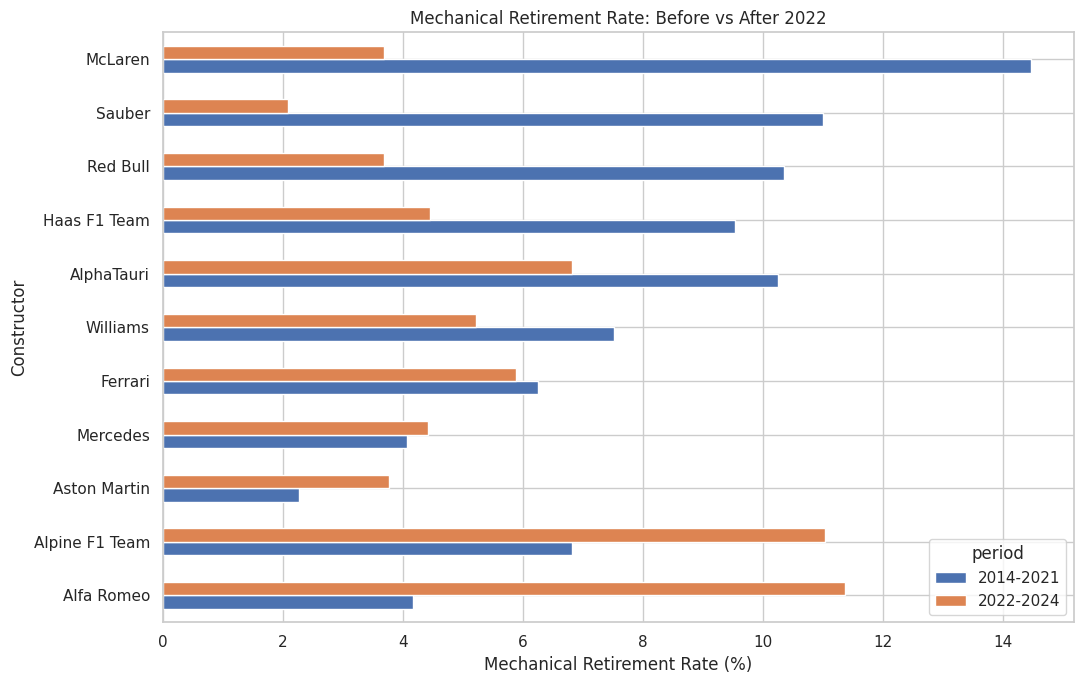


=== FINAL ANSWER: HIGHEST MECHANICAL RETIREMENT RATE ===
2014-2021: Caterham - 23.53% (8 retirements / 34 starts)
2022-2024: Alfa Romeo - 11.36% (10 retirements / 88 starts)

=== FINAL CHECKS ===
Total race starts analyzed: 4612
Total mechanical retirements: 388
Missing status descriptions: 0
Duplicate race-driver records: 0

Question 3 completed.


In [40]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# QUESTION 3: MECHANICAL RETIREMENT RATES BY CONSTRUCTOR

sns.set_theme(style="whitegrid")

# 1. JOIN THE TABLES

mechanical = clean["results"][[
    "raceId", "driverId", "constructorId",
    "grid", "laps", "statusId"
]].merge(
    clean["races"][["raceId", "year"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["constructors"][["constructorId", "name"]],
    on="constructorId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

mechanical = mechanical.rename(
    columns={"name": "constructor"}
)

# 2. KEEP 2014 TO 2024

mechanical = mechanical[
    mechanical["year"].between(2014, 2024)
].copy()

mechanical["period"] = np.where(
    mechanical["year"] <= 2021,
    "2014-2021",
    "2022-2024"
)

# 3. DEFINE MECHANICAL FAILURES

mechanical_reasons = [
    "Engine",
    "Gearbox",
    "Transmission",
    "Clutch",
    "Hydraulics",
    "Electrical",
    "Electronics",
    "Suspension",
    "Brakes",
    "Brake duct",
    "Brake failure",
    "Wheel",
    "Wheel bearing",
    "Wheel nut",
    "Driveshaft",
    "Differential",
    "Alternator",
    "Battery",
    "Fuel system",
    "Fuel pump",
    "Fuel pressure",
    "Fuel leak",
    "Oil leak",
    "Oil pressure",
    "Oil pump",
    "Water leak",
    "Water pressure",
    "Water pump",
    "Cooling system",
    "Radiator",
    "Overheating",
    "Turbo",
    "Turbocharger",
    "Power Unit",
    "Power loss",
    "ERS",
    "MGU-K",
    "MGU-H",
    "Exhaust",
    "Throttle",
    "Steering",
    "Pneumatics",
    "Ignition",
    "Spark plugs",
    "Injection",
    "Vibrations",
    "Mechanical"
]

mechanical_set = {
    reason.lower() for reason in mechanical_reasons
}

mechanical["is_mechanical"] = (
    mechanical["status"]
    .fillna("")
    .str.strip()
    .str.lower()
    .isin(mechanical_set)
    .astype(int)
)

# 4. EXCLUDE DRIVERS WHO DID NOT START

non_start_reasons = [
    "Did not start",
    "Did not qualify",
    "Did not prequalify",
    "Withdrawn",
    "Withdrew",
    "Not classified as a starter"
]

non_start_set = {
    reason.lower() for reason in non_start_reasons
}

mechanical["is_start"] = ~(
    mechanical["status"]
    .fillna("")
    .str.strip()
    .str.lower()
    .isin(non_start_set)
)

print("=== NON-START ENTRIES EXCLUDED ===")

display(
    mechanical[~mechanical["is_start"]]["status"]
    .value_counts()
    .reset_index()
)

mechanical = mechanical[
    mechanical["is_start"]
].copy()

# 5. CHECK MECHANICAL FAILURE REASONS

print("\n=== MECHANICAL FAILURE REASONS ===")

failure_counts = (
    mechanical[mechanical["is_mechanical"] == 1]
    ["status"]
    .value_counts()
    .reset_index()
)

display(failure_counts)

# 6. CHECK ZERO-LAP MECHANICAL FAILURES
# Zero completed laps does not necessarily mean no start.
# A driver may retire during the first lap.

mechanical["laps"] = pd.to_numeric(
    mechanical["laps"], errors="coerce"
)

zero_lap_failures = mechanical[
    (mechanical["is_mechanical"] == 1) &
    (mechanical["laps"] == 0)
]

print("\n=== MECHANICAL FAILURES WITH ZERO LAPS ===")
print("Total:", len(zero_lap_failures))

display(
    zero_lap_failures[[
        "year", "constructor", "status", "grid", "laps"
    ]]
)

# 7. CALCULATE MECHANICAL RETIREMENT RATES

rates3 = mechanical.groupby(
    ["constructor", "period"]
)["is_mechanical"].agg(
    starts="size",
    mechanical_retirements="sum"
).reset_index()

rates3["retirement_rate"] = (
    rates3["mechanical_retirements"] /
    rates3["starts"] * 100
)

# Minimum 20 race starts in each period.
rates3 = rates3[
    rates3["starts"] >= 20
].copy()

rates3 = rates3.sort_values(
    ["period", "retirement_rate"],
    ascending=[True, False]
)

print("\n=== MECHANICAL RETIREMENT RATES BY CONSTRUCTOR ===")

display(rates3.round(2))

# 8. TOP CONSTRUCTORS IN EACH PERIOD

print("\n=== TOP 10 CONSTRUCTORS IN EACH PERIOD ===")

top3 = (
    rates3.groupby("period", group_keys=False)
    .head(10)
)

display(top3.round(2))

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top3,
    x="retirement_rate",
    y="constructor",
    hue="period",
    errorbar=None
)

plt.title("Mechanical Retirement Rate by Constructor")
plt.xlabel("Mechanical Retirements per 100 Race Starts (%)")
plt.ylabel("Constructor")
plt.tight_layout()
plt.show()

# 9. COMPARE CONSTRUCTORS PRESENT IN BOTH PERIODS

comparison3 = rates3.pivot(
    index="constructor",
    columns="period",
    values="retirement_rate"
).dropna()

comparison3["Difference (pp)"] = (
    comparison3["2022-2024"] -
    comparison3["2014-2021"]
)

comparison3 = comparison3.sort_values(
    "Difference (pp)", ascending=False
)

print("\n=== CONSTRUCTOR COMPARISON BETWEEN PERIODS ===")

display(comparison3.round(2))

if not comparison3.empty:
    comparison3[["2014-2021", "2022-2024"]].plot(
        kind="barh",
        figsize=(11, 7)
    )

    plt.title("Mechanical Retirement Rate: Before vs After 2022")
    plt.xlabel("Mechanical Retirement Rate (%)")
    plt.ylabel("Constructor")
    plt.tight_layout()
    plt.show()

# 10. FINAL ANSWER

print("\n=== FINAL ANSWER: HIGHEST MECHANICAL RETIREMENT RATE ===")

for period in ["2014-2021", "2022-2024"]:
    period_data = rates3[
        rates3["period"] == period
    ].sort_values("retirement_rate", ascending=False)

    if not period_data.empty:
        winner = period_data.iloc[0]

        print(
            f"{period}: {winner['constructor']} - "
            f"{winner['retirement_rate']:.2f}% "
            f"({int(winner['mechanical_retirements'])} "
            f"retirements / {int(winner['starts'])} starts)"
        )

# 11. FINAL QUALITY CHECKS

print("\n=== FINAL CHECKS ===")

print("Total race starts analyzed:", len(mechanical))
print("Total mechanical retirements:", mechanical["is_mechanical"].sum())
print("Missing status descriptions:", mechanical["status"].isna().sum())
print(
    "Duplicate race-driver records:",
    mechanical.duplicated(["raceId", "driverId"]).sum()
)

print("\nQuestion 3 completed.")


In [41]:
### Question 3 — Mechanical Retirement Rates

##We joined results, races, constructors, and status. Each row represents one driver-race entry.

##Mechanical retirements were identified from car-component failure statuses, excluding crashes, driver-related incidents, regulatory decisions, and known non-starts.

##Caterham had the highest mechanical-retirement rate in 2014–2021 (23.53%, 8/34 starts). Alfa Romeo had the highest rate in 2022–2024 (11.36%, 10/88 starts).

##We required at least 20 starts per constructor per period. Zero-lap mechanical failures were retained because a driver can retire during the first lap. Missing or ambiguous failure reasons were not classified as mechanical.

##Mechanical-retirement status is known only after the race.